# 09 · Model comparison: GLMs vs XGBoost (Milestone 11)

**The question:** which model should the app use to show area-level expected flood loss cost: the GLM champion (frequency × severity + Bühlmann–Straub county factor), a GLM with interactions, or XGBoost?

*Area-level analysis of aggregated public data: every number describes the average for a group of similar insured buildings, never a prediction for an individual property.*

**How it's computed.** `src/models/compare.py` refits **every** model on the same training years and scores it on the same unseen rows. That's 16-year leave-one-year-out (the headline), the 11 development folds, and the 2021–2025 holdout. XGBoost settings are frozen from Milestone 10, with no re-tuning. The expensive part (about 7 minutes) runs once with `.venv\Scripts\python.exe src\models\compare.py run`, and this notebook reads its cached results. Set `RERUN = True` to recompute.

**Decision rule.** It was written in `PROGRESS.md` before any of these results existed (Milestone 11 decisions).

In [1]:
import hashlib
import json
import subprocess
import sys
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "src" / "models"))
import validation as val
from models import frequency_glm as fg
from models import severity_glm as sv
from models import pure_premium as pp
from models import xgb_models as X
from models import compare as C
from models import production

warnings.filterwarnings("ignore")
FIG, REP = ROOT / "reports" / "figures", ROOT / "reports"
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 230)
pd.set_option("display.max_colwidth", 60)
RERUN = False

# Palette: slots 1-3 of the validated reference categorical palette (same as notebooks 01-08):
# XGBoost = blue, GLM champion = orange, hybrid GLM = aqua; secondary models in neutral ink.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
CAT_SHADE = "#f1efe8"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "font.size": 9.5,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "legend.frameon": False, "text.usetex": False, "text.parse_math": False,
})

def save(fig, name):
    path = FIG / f"09_{name}.png"
    fig.savefig(path)
    print(f"saved {path.relative_to(ROOT)}")

def log_axis(ax, lo, hi, axis="y", ticks=(0.05, 0.1, 0.25, 0.5, 0.67, 0.8, 1, 1.25, 1.5, 2, 4, 8)):
    a = ax.yaxis if axis == "y" else ax.xaxis
    (ax.set_yscale if axis == "y" else ax.set_xscale)("log")
    (ax.set_ylim if axis == "y" else ax.set_xlim)(lo, hi)
    a.set_major_locator(mticker.FixedLocator([t for t in ticks if lo <= t <= hi]))
    a.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:g}"))
    a.set_minor_locator(mticker.NullLocator())

LABELS = {"flood_zone_group": "Flood zone", "occupancy_group": "Occupancy", "floors_group": "Floors",
          "elevated": "Elevated", "primary_residence": "Primary residence", "post_firm": "Post-FIRM",
          "construction_band": "Year built", "building_coverage_band": "Building coverage",
          "coastal_tidal": "Tidewater", "county_group": "County group"}
CHAMP = C.CHAMPION
HYB = "Hybrid GLM fxs + county"
PP_COL = {CHAMP: ORANGE, HYB: AQUA, "XGB fxs": BLUE, "XGB Tweedie": INK_2,
          "GLM fxs": MUTED, "GLM Tweedie": MUTED, "XGB fxs no-geo + county": MUTED}
KIND_LABEL = {"frequency": "Frequency (Poisson deviance)", "severity": "Severity (Gamma deviance)",
              "pure_premium": "Pure premium (Tweedie p = 1.5 deviance)"}
GLM_OF = {"frequency": "GLM Poisson", "severity": "GLM Gamma", "pure_premium": CHAMP}

In [2]:
if RERUN:
    subprocess.run([sys.executable, str(ROOT / "src" / "models" / "compare.py"), "run"], check=True)
D = C.load_data()
spec = json.loads(C.cache_path("hybrid_spec").with_suffix(".json").read_text())
D["hybrid"] = spec
SC = {d: pd.read_csv(REP / f"08_scores_{d}.csv") for d in ("loyo16", "dev", "holdout")}
for d in ("loyo16", "dev"):
    SC[d]["test_year"] = SC[d]["test_year"].astype(int)
OOF = {(k, d): pd.read_parquet(C.cache_path(f"oof_{k}_{d}")) for k in ("frequency", "severity", "pure_premium")
       for d in ("loyo16", "dev", "holdout")}
GR = pd.read_parquet(C.cache_path("grid_rates"))
raw = D["raw"]
GRID_CELLS = raw[(raw["year"] == 2025) & (raw["exposure"] > 0)].reset_index(drop=True)
print("hybrid spec:", spec)
print({d: len(s) for d, s in SC.items()}, "score rows")

raw cells 252,531 | XGB table 170,806 | severity claims 9,553 | all paid claims 9,557
hybrid spec: {'freq_features': ['flood_zone_group', 'construction_band', 'floors_group'], 'freq_inter': [['construction_band', 'flood_zone_group']], 'sev_features': ['occupancy_group', 'construction_band', 'building_coverage_band', 'flood_zone_group', 'floors_group', 'primary_residence', 'elevated'], 'sev_inter': [['building_coverage_band', 'occupancy_group'], ['elevated', 'flood_zone_group']]}
{'loyo16': 240, 'dev': 165, 'holdout': 90} score rows


## 1. Is the comparison fair?
A fair comparison needs the **same data, the same folds, the same test rows, the same loss treatment and the same yardstick** for every model. The checks below are assertions: if any fails, the notebook stops.

In [3]:
# (a) the data file is the one every saved model was built from
h = hashlib.sha256(X.CELLS_PATH.read_bytes()).hexdigest()[:16]
pj = json.loads((ROOT / "models" / "pure_premium.json").read_text())
print("data hash", h, "| pure_premium.json was built from", pj["data_file_sha256_16"])
same_data = h == pj["data_file_sha256_16"]

# (b) refitting on all 16 years reproduces the saved GLMs and the saved XGBoost trees
ALL = C.fit_split(D, val.ALL_YEARS)
freq0, sev0, _ = pp.load_saved_models()
assert np.allclose(ALL["freq/GLM Poisson"].params, freq0.params) and np.allclose(ALL["sev/GLM Gamma"].params, sev0.params)
saved = {k: X.XGBModel.load_model(ROOT / "models" / f"xgb_{k}_all") for k in ("frequency", "severity", "tweedie")}
for k, key in (("frequency", "freq/XGB"), ("severity", "sev/XGB"), ("tweedie", "pp/XGB Tweedie")):
    assert np.allclose(saved[k].rate(GRID_CELLS), ALL[key].rate(GRID_CELLS), rtol=1e-5), k
print("All-years refits reproduce models/frequency_glm.json, severity_glm.json and the three xgb_*_all models.")

# (c) Milestone 9's per-fold pure-premium scores (raw county cells) are reproduced exactly
m9 = pd.read_csv(REP / "06_loyo_scores.csv")
for old, new in (("freq x sev", "GLM fxs"), ("freq x sev + county (buhlmann_straub)", CHAMP), ("Tweedie p=1.7", "GLM Tweedie")):
    a = m9[m9.model == old].set_index("test_year")["improvement_rebased_pct"]
    b = SC["loyo16"].query("kind == 'pure_premium' and model == @new").set_index("test_year")["improvement_rebased_pct"]
    assert np.allclose(a.sort_index(), b.sort_index()), old
# (d) Milestone 10's holdout scores for frequency and severity (same tables) are reproduced
m10 = pd.read_csv(REP / "07_xgb_preview_vs_glm.csv")
hp = SC["holdout"][SC["holdout"].test_year == "pooled"]
for kind, k10, glm in (("frequency", "frequency", "GLM Poisson"), ("severity", "severity", "GLM Gamma")):
    for meth, name in (("XGBoost", "XGB"), ("GLM", glm)):
        v10 = m10.query("model == @k10 and method == @meth")["holdout %"].iloc[0]
        v11 = hp.query("kind == @kind and model == @name")["improvement_rebased_pct"].iloc[0]
        assert np.isclose(v10, v11), (kind, meth, v10, v11)
print("Milestone 9 (16-year LOYO) and Milestone 10 (holdout) numbers reproduced exactly.")

# (e) identical test rows: every model has a prediction for every test row, each row tested once
for (k, d), o in OOF.items():
    models = [c for c in o.columns if c in C.FREQ_MODELS + C.SEV_MODELS + C.PP_MODELS]
    assert o[models].notna().all().all() and np.isfinite(o[models].to_numpy()).all()
pt = OOF[("pure_premium", "loyo16")]
assert len(pt) == int((raw["exposure"] > 0).sum()) and not pt.duplicated(["year", "county", *X.ALL_FEATURES]).any()
assert len(OOF[("severity", "loyo16")]) == len(D["sevdf"]) and len(OOF[("frequency", "loyo16")]) == len(D["xcells"])
print("Every model is scored on exactly the same rows; every row is tested exactly once.")

data hash d554de463a01678d | pure_premium.json was built from d554de463a01678d


All-years refits reproduce models/frequency_glm.json, severity_glm.json and the three xgb_*_all models.
Milestone 9 (16-year LOYO) and Milestone 10 (holdout) numbers reproduced exactly.
Every model is scored on exactly the same rows; every row is tested exactly once.


In [4]:
xs = D["settings"]
audit = pd.DataFrame([
    ("Data file", f"va_model_data.parquet (hash {h})", "same file", "yes" if same_data else "NO"),
    ("Training rows", "cells with exposure > 0; 9,553 claims (b+c > 0)", "same rows (frequency/Tweedie summed over 10 features + year)", "yes"),
    ("Folds", "16-year LOYO, 11 dev folds, 2010-20 -> 2021-25 holdout", "same splits, same test rows (asserted)", "yes"),
    ("Year handling", "calendar-year factor, average-year prediction", "year level in base_margin, average-year prediction", "equivalent"),
    ("Loss treatment", "2025 $, uncapped (load 1.000), ICC bridge, off-balance per fold", "same (same CombinedModel code for freq x sev)", "yes"),
    ("Unmatched claims (95)", "added back by the off-balance", "same (freq x sev); Tweedie off-balance", "yes"),
    ("Features offered", "frequency: zone, year built, floors; severity: 7 (selected by keep rule)",
     "all 8 building features (+ Tidewater + county group for severity & Tweedie)", "DIFFERENT (by design)"),
    ("Geography", "Buhlmann-Straub county factor on top (champion)", "county group inside the severity trees", "DIFFERENT (compared both ways)"),
    ("Tuning / selection", "features chosen on dev LOYO (2010-20)", "hyperparameters chosen on dev LOYO (2010-20)", "comparable optimism"),
    ("Yardstick", "re-based deviance improvement vs no-features model, each year once; Gini", "same functions", "yes"),
], columns=["item", "GLM", "XGBoost", "same?"])
audit.to_csv(REP / "08_fair_setup.csv", index=False)
audit

,item,GLM,XGBoost,same?
0,Data file,va_model_data.parquet (hash d554de463a01678d),same file,yes
1,Training rows,"cells with exposure > 0; 9,553 claims (b+c > 0)",same rows (frequency/Tweedie summed over 10 features + y...,yes
2,Folds,"16-year LOYO, 11 dev folds, 2010-20 -> 2021-25 holdout","same splits, same test rows (asserted)",yes
3,Year handling,"calendar-year factor, average-year prediction","year level in base_margin, average-year prediction",equivalent
4,Loss treatment,"2025 $, uncapped (load 1.000), ICC bridge, off-balance p...",same (same CombinedModel code for freq x sev),yes
5,Unmatched claims (95),added back by the off-balance,same (freq x sev); Tweedie off-balance,yes
6,Features offered,"frequency: zone, year built, floors; severity: 7 (select...",all 8 building features (+ Tidewater + county group for ...,DIFFERENT (by design)
7,Geography,Buhlmann-Straub county factor on top (champion),county group inside the severity trees,DIFFERENT (compared both ways)
8,Tuning / selection,features chosen on dev LOYO (2010-20),hyperparameters chosen on dev LOYO (2010-20),comparable optimism
9,Yardstick,"re-based deviance improvement vs no-features model, each...",same functions,yes


**Result: the comparison is fair where it should be, and the differences are deliberate.**
- **The same:** data file, training rows, folds, test rows, year handling, loss treatment and yardstick. Milestone 9's per-fold pure-premium scores and Milestone 10's holdout scores reproduce exactly, so this notebook compares like with like with the earlier milestones.
- **Different, by design:**
  - *Features.* XGBoost was offered all 10 candidate features. The GLMs kept only the ones that passed the storm-aware keep rule. That's the point of the comparison: can flexibility find signal the rule threw away?
  - *Geography.* XGBoost severity has county group in its trees, while the champion adds a Bühlmann–Straub county factor on top. To see both like for like, there's also **"XGB fxs no-geo + county"**: XGBoost without geography plus the *same* credibility county factor as the GLM.
- **Selection optimism is similar.** Both were chosen on the 2010–2020 folds. The holdout is clean for both.

## 2. Accuracy on unseen years: the scorecard
**Improvement %** = how much lower each model's re-based deviance is than a no-features model on a year it never saw, with each year counting once. **Gini** = how well it ranks cells from low to high risk (0 = random). **Holdout** = trained 2010–2020, scored once on 2021–2025.

In [5]:
def scorecard(kind):
    lo, dv = C.summarize(SC["loyo16"], kind), C.summarize(SC["dev"], kind)
    hp = SC["holdout"].query("kind == @kind and test_year == 'pooled'").set_index("model")
    glm = GLM_OF[kind]
    t = pd.DataFrame({"LOYO-16 mean %": lo["mean_improvement"], "normal yrs %": lo["normal_years"],
                      "cat yrs %": lo["cat_years"], "LOYO-16 Gini": lo["gini"],
                      "years beating " + ("champion" if kind == "pure_premium" else "GLM"):
                          [C.wins_vs(SC["loyo16"], kind, glm, m)["b_wins"] if m != glm else np.nan for m in lo.index],
                      "dev-LOYO %": dv["mean_improvement"], "holdout %": hp["improvement_rebased_pct"],
                      "holdout Gini": hp["gini"], "holdout raw A/E": hp["actual_over_expected"]})
    return t

CARD = {k: scorecard(k) for k in ("frequency", "severity", "pure_premium")}
# county-level fit (held-out county A/E, 38 counties with >= 30 claims), Milestone 9's measure
cty = {m: pp.county_ae_out_of_fold(OOF[("pure_premium", "loyo16")], m)[1]["mean_abs_log_ae"] for m in C.PP_MODELS}
CARD["pure_premium"]["county mean |log A/E|"] = pd.Series(cty)
pd.concat(CARD, names=["kind", "model"]).round(3).to_csv(REP / "08_scorecard.csv")
for k, t in CARD.items():
    print(KIND_LABEL[k]); print(t.round(3).to_string()); print()

Frequency (Poisson deviance)
             LOYO-16 mean %  normal yrs %  cat yrs %  LOYO-16 Gini  years beating GLM  dev-LOYO %  holdout %  holdout Gini  holdout raw A/E
model                                                                                                                                      
GLM Poisson           4.726         2.549     14.161         0.299                NaN       5.579      2.213         0.263            0.201
Hybrid GLM            4.766         2.679     13.811         0.296                9.0       5.658      2.180         0.255            0.201
GLM NB                5.192         3.465     12.676         0.301               12.0       6.072      3.100         0.264            0.202
XGB                   6.517         5.524     10.816         0.350               14.0       6.752      4.344         0.326            0.196

Severity (Gamma deviance)
            LOYO-16 mean %  normal yrs %  cat yrs %  LOYO-16 Gini  years beating GLM  dev-LOYO %  holdou

saved reports\figures\09_scorecard.png


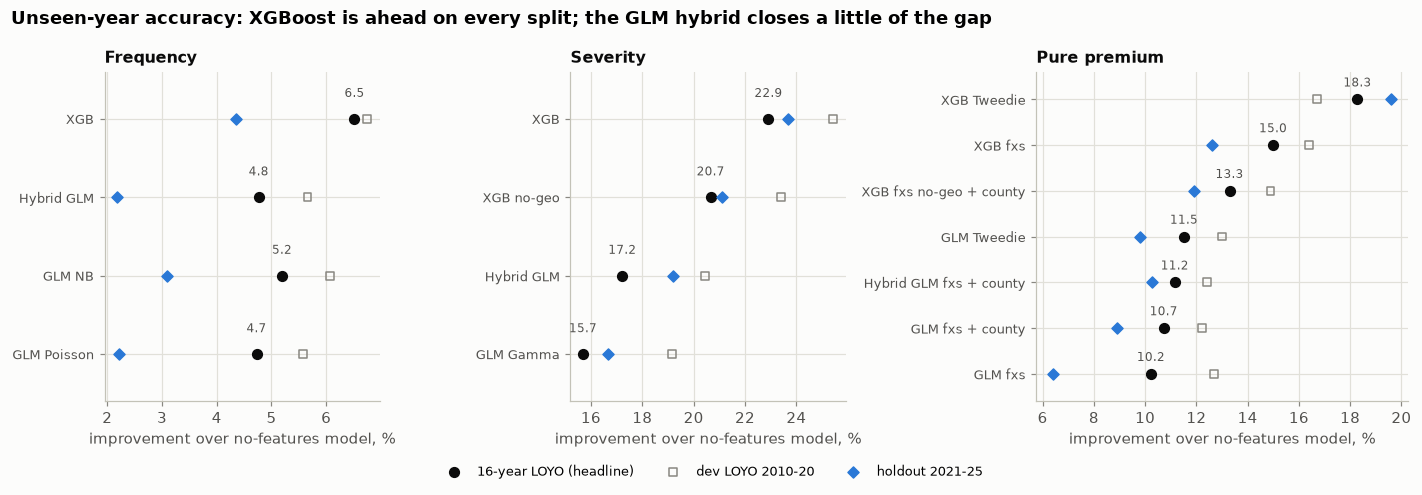

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.35]})
order = {"frequency": ["GLM Poisson", "GLM NB", "Hybrid GLM", "XGB"],
         "severity": ["GLM Gamma", "Hybrid GLM", "XGB no-geo", "XGB"],
         "pure_premium": ["GLM fxs", CHAMP, HYB, "GLM Tweedie", "XGB fxs no-geo + county", "XGB fxs", "XGB Tweedie"]}
for ax, k in zip(axes, order):
    t = CARD[k].loc[order[k]]
    y = np.arange(len(t))
    for col, mk, lab, c in (("LOYO-16 mean %", "o", "16-year LOYO (headline)", INK), ("dev-LOYO %", "s", "dev LOYO 2010-20", MUTED),
                            ("holdout %", "D", "holdout 2021-25", BLUE)):
        ax.scatter(t[col], y, marker=mk, s=40 if mk == "o" else 26, color=c, zorder=3, label=lab,
                   facecolor=c if mk != "s" else "none")
    for yy, v in zip(y, t["LOYO-16 mean %"]):
        ax.text(v, yy + 0.28, f"{v:.1f}", ha="center", fontsize=8, color=INK_2)
    ax.set_yticks(y, t.index, fontsize=8.5)
    ax.set_ylim(-0.6, len(t) - 0.4)
    ax.set_xlabel("improvement over no-features model, %")
    ax.set_title(KIND_LABEL[k].split(" (")[0], fontsize=10.5)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=8.5, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Unseen-year accuracy: XGBoost is ahead on every split; the GLM hybrid closes a little of the gap",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "scorecard")
plt.show()

**Reading the scorecard (pure premium, 16-year LOYO):**

| Model | Improvement | Gini | Holdout |
|---|---|---|---|
| Champion (GLM freq × sev + county) | 10.7% | 0.473 | 8.9% |
| Hybrid GLM | 11.2% | 0.481 | 10.3% |
| XGBoost freq × sev | **15.0%** | **0.533** | **12.6%** |
| XGBoost Tweedie | **18.3%** | **0.596** | **19.6%** |

- XGBoost freq × sev beats the champion in **15 of 16** unseen years.
- **Frequency:** XGBoost is ahead on average (6.5% vs 4.7%) but **behind in catastrophe years** (10.8% vs 14.2%). The negative binomial is slightly ahead of the Poisson (5.2%).
- **Severity:** the gap is largest here (22.9% vs 15.7%). Even without county in the trees, XGBoost keeps most of it (20.7%).
- **County-level fit:** the champion is best (mean |log A/E| 0.34 vs 0.41 for XGBoost freq × sev). The credibility county factor is doing its job.

### A/E by year (raw: no re-basing)
Every model predicts an **average year**, so a hurricane year shows as A/E far above 1 and a quiet year far below. Here the models are almost indistinguishable: none of them can forecast the weather.

saved reports\figures\09_ae_by_year.png


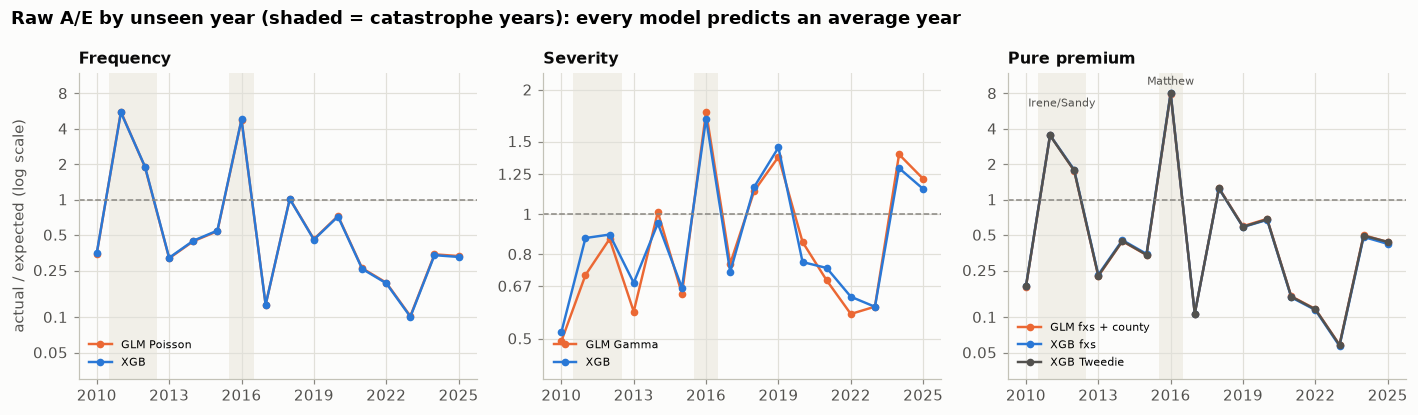

test_year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
model,,,,,,,,,,,,,,,,
GLM fxs + county,0.18,3.54,1.77,0.22,0.44,0.34,7.94,0.11,1.26,0.59,0.69,0.15,0.12,0.06,0.50,0.44
Hybrid GLM fxs + county,0.18,3.58,1.78,0.23,0.45,0.34,7.96,0.11,1.26,0.59,0.68,0.15,0.12,0.06,0.49,0.43
XGB fxs,0.18,3.54,1.80,0.23,0.45,0.35,8.09,0.11,1.24,0.59,0.67,0.15,0.12,0.06,0.48,0.42
XGB Tweedie,0.18,3.52,1.77,0.23,0.45,0.34,8.01,0.11,1.25,0.59,0.68,0.15,0.12,0.06,0.49,0.44


In [7]:
s = SC["loyo16"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
yrs = np.array(val.ALL_YEARS)
for ax, k, models in ((axes[0], "frequency", ["GLM Poisson", "XGB"]), (axes[1], "severity", ["GLM Gamma", "XGB"]),
                      (axes[2], "pure_premium", [CHAMP, "XGB fxs", "XGB Tweedie"])):
    for cy in val.CAT_YEARS:
        ax.axvspan(cy - 0.5, cy + 0.5, color=CAT_SHADE, zorder=0, lw=0)
    for m in models:
        t = s.query("kind == @k and model == @m").set_index("test_year")["actual_over_expected"].reindex(yrs)
        c = {"GLM Poisson": ORANGE, "GLM Gamma": ORANGE, "XGB": BLUE}.get(m, PP_COL.get(m))
        ax.plot(yrs, t, marker="o", ms=4, lw=1.6, color=c, label=m)
    ax.axhline(1, color=MUTED, ls="--", lw=1)
    log_axis(ax, 0.03 if k != "severity" else 0.4, 12 if k != "severity" else 2.2,
             ticks=(0.05, 0.1, 0.25, 0.5, 1, 2, 4, 8) if k != "severity" else (0.5, 0.67, 0.8, 1, 1.25, 1.5, 2))
    ax.set_title(KIND_LABEL[k].split(" (")[0], fontsize=10.5)
    ax.legend(fontsize=7.5, loc="lower left")
axes[0].set_ylabel("actual / expected (log scale)")
for ax in axes:
    ax.set_xticks([2010, 2013, 2016, 2019, 2022, 2025])
axes[2].text(2016, 9.5, "Matthew", ha="center", fontsize=7.5, color=INK_2)
axes[2].text(2011.5, 6.2, "Irene/Sandy", ha="center", fontsize=7.5, color=INK_2)
fig.suptitle("Raw A/E by unseen year (shaded = catastrophe years): every model predicts an average year",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "ae_by_year")
plt.show()
aey = s.query("kind == 'pure_premium'").pivot(index="test_year", columns="model", values="actual_over_expected")
aey.round(2).to_csv(REP / "08_ae_by_year.csv")
aey[[CHAMP, HYB, "XGB fxs", "XGB Tweedie"]].round(2).T

**Result.** Raw A/E by year moves in lockstep for every model (2016: 7.9–8.1; 2023: 0.06). No model forecasts weather, and every model prices an average year. Accuracy differences show up only once each year's level is removed: the re-based scores and the segment checks below.

### A/E by segment (out of fold, re-based within each year)
Re-basing removes each year's storm level, so 1.00 means the model puts the right *share* of that year's losses on the segment. Above 1 = under-predicted; below 1 = over-predicted. The grey band is 0.8–1.25, the decision rule's tolerance.

In [8]:
po = OOF[("pure_premium", "loyo16")]
SEG_FEATS = ["flood_zone_group", "elevated", "building_coverage_band", "occupancy_group", "construction_band", "county_group"]
SEG = C.segment_ae(po, C.PP_MODELS, SEG_FEATS, X.LOSS)
cg_claims = po.groupby("county_group")["claims"].sum()
big_cg = cg_claims[cg_claims >= 150].index.astype(str)          # credible county groups for display
SEG["shown"] = (SEG.feature != "county_group") | SEG.level.isin(big_cg)
SEG.to_csv(REP / "08_segment_ae.csv", index=False)
wide = SEG[SEG.shown].pivot_table(index=["feature", "level"], columns="model", values="ae", sort=False)
wide[[CHAMP, HYB, "XGB fxs", "XGB Tweedie", "GLM Tweedie"]].round(2)

model                                           GLM fxs + county  Hybrid GLM fxs + county  XGB fxs  XGB Tweedie  GLM Tweedie
feature                level                                                                                                
flood_zone_group       A/V high risk                        1.00                     0.99     1.05         1.10         1.04
                       B/C/X moderate-low risk              1.00                     1.03     0.87         0.76         0.90
elevated               False                                1.06                     1.05     1.09         1.07         1.00
                       True                                 0.88                     0.90     0.82         0.86         1.00
building_coverage_band $0 (contents only)                   1.45                     1.35     0.97         0.71         0.99
                       $100K-$249K                          1.11                     1.17     1.13         1.11         1.10
                       $250K or more                        0.98                     0.93     0.96         1.06         1.21
                       under $100K                          0.74                     0.85     0.82         0.59         0.41
occupancy_group        multi-unit residential               1.30                     1.19     1.15         1.59         1.21
                       non-residential                      0.70                     0.67     0.84         0.74         0.47
                       single-unit residential              1.03                     1.06     1.00         0.98         1.19
construction_band      1960-1979                            1.11                     1.11     1.17         1.22         1.13
                       1980-1999                            1.00                     1.00     0.92         0.88         0.90
                       2000 or later                        0.96                     0.96     0.69         0.71         0.89
                       before 1960                          0.82                     0.83     0.85         0.80         0.85
county_group           51001                                0.76                     0.73     0.76         0.97         0.90
                       51059                                0.81                     0.82     0.91         0.79         0.90
                       51510                                0.98                     0.93     1.39         0.96         1.27
                       51550                                0.85                     0.82     0.78         1.07         0.73
                       51650                                0.62                     0.64     0.57         0.88         0.51
                       51700                                1.55                     1.59     2.53         2.34         3.04
                       51710                                0.94                     0.94     0.90         1.09         0.89
                       51735                                0.79                     0.80     0.73         0.79         0.87
                       51740                                1.06                     1.06     1.11         1.09         0.92
                       51810                                1.58                     1.57     1.60         2.04         2.03
                       Other non-tidal (small)              1.07                     1.07     1.04         0.55         0.87
                       Other tidal (small)                  0.67                     0.64     0.71         0.71         0.62

saved reports\figures\09_segment_ae.png


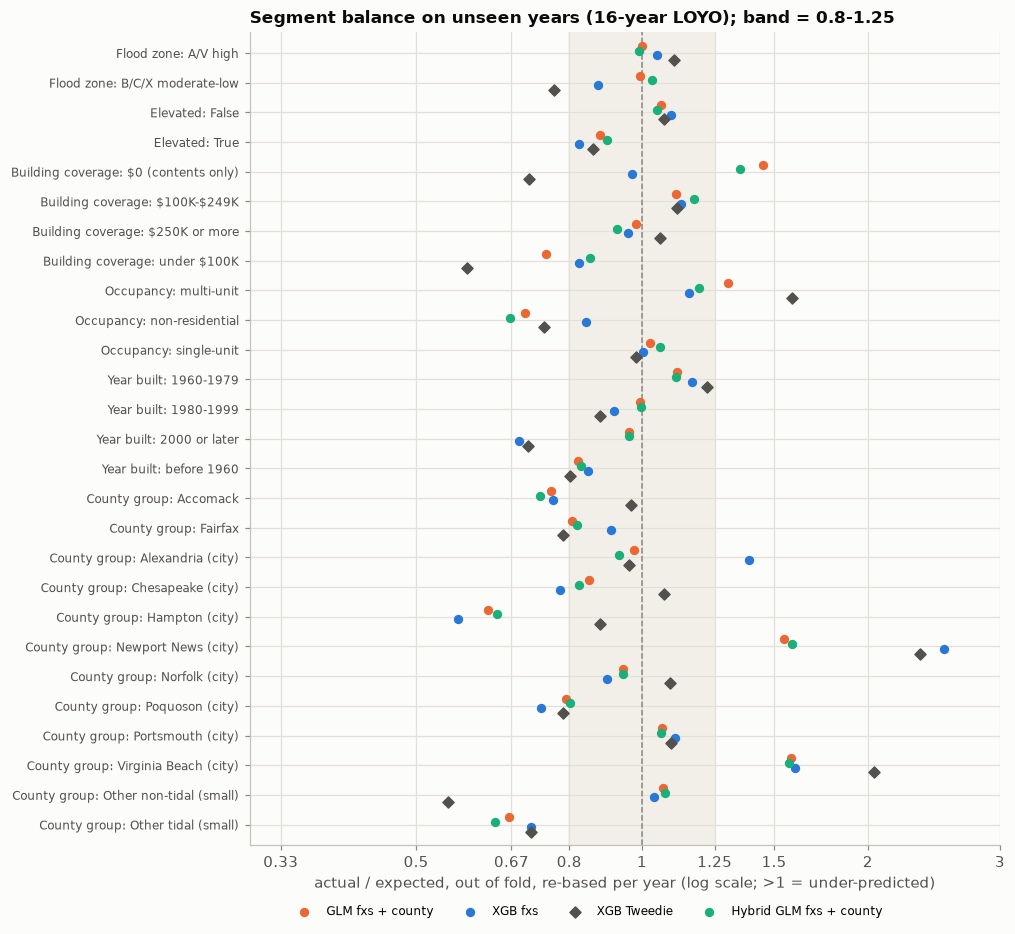

In [9]:
show = SEG[SEG.shown & SEG.model.isin([CHAMP, HYB, "XGB fxs", "XGB Tweedie"])].copy()
CNAME = {r["county"]: r["name"].replace(" city", " (city)").replace(" County", "") for r in json.loads((ROOT / "models" / "pure_premium.json").read_text())["county_table"]}
show["label"] = show.feature.map(LABELS) + ": " + show.level.map(lambda l: CNAME.get(l, l)).str.replace(" residential", "").str.replace(" risk", "")
labs = list(dict.fromkeys(show.label))
fig, ax = plt.subplots(figsize=(8.8, 9.6))
yy = {l: i for i, l in enumerate(labs[::-1])}
ax.axvspan(0.8, 1.25, color=CAT_SHADE, zorder=0)
off = {CHAMP: 0.24, HYB: 0.08, "XGB fxs": -0.08, "XGB Tweedie": -0.24}
for m, g in show.groupby("model", sort=False):
    ax.scatter(g.ae.clip(0.3, 3), [yy[l] + off[m] for l in g.label], s=26, color=PP_COL[m], label=m, zorder=3,
               marker="D" if m == "XGB Tweedie" else "o")
ax.set_yticks(list(yy.values()), list(yy.keys()), fontsize=7.8)
ax.set_ylim(-0.7, len(labs) - 0.3)
log_axis(ax, 0.3, 3, axis="x", ticks=(0.33, 0.5, 0.67, 0.8, 1, 1.25, 1.5, 2, 3))
ax.axvline(1, color=MUTED, ls="--", lw=1)
ax.set_xlabel("actual / expected, out of fold, re-based per year (log scale; >1 = under-predicted)")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.06), ncol=4, fontsize=8)
ax.set_title("Segment balance on unseen years (16-year LOYO); band = 0.8-1.25", loc="left")
save(fig, "segment_ae")
plt.show()

**Result: segments (1.00 = right share of each year's losses).**
- **Champion:** carries the imbalances Milestone 9 flagged: contents-only 1.45, multi-unit 1.30, under-$100K coverage 0.74, non-residential 0.70.
- **Hybrid:** the coverage × occupancy interaction pulls three of them in: contents-only 1.35, multi-unit 1.19, under-$100K 0.85. Non-residential stays low (0.67).
- **XGBoost freq × sev:** balances occupancy and coverage best (all 0.82–1.15). But it **over-predicts buildings from 2000 or later (0.69)**, confirming Milestone 10's warning, and puts B/C/X zones at 0.87.
- **XGBoost Tweedie:** the most unbalanced: multi-unit 1.59, under-$100K 0.59, contents-only 0.71, B/C/X 0.76.
- **Counties:** Newport News (51700) and Virginia Beach (51810) stay under-predicted by every model out of fold. Both are hurricane-exposed places where a held-out storm year can't be learned from the other years.

## 3. Ranking: lift, Gini and double lift
**Lift chart:** sort the unseen cells from lowest to highest predicted risk, cut them into 10 groups with equal exposure, and compare actual with predicted in each group. A steeper, better-matched staircase is better. **Double lift:** sort by the *ratio* of two models' predictions. At the ends, where they disagree most, whichever line follows the actual bars is right.

In [10]:
def lift(actual, pred_rb, weight, rank, n=10):
    order = np.argsort(np.asarray(rank, float), kind="mergesort")
    a, p, w = (np.asarray(v, float)[order] for v in (actual, pred_rb, weight))
    cum = np.cumsum(w) / w.sum()
    b = np.minimum((cum * n - 1e-12).astype(int), n - 1) + 1
    t = pd.DataFrame({"decile": b, "w": w, "a": a, "p": p}).groupby("decile").sum()
    avg = a.sum() / w.sum()
    t["actual_rel"], t["pred_rel"] = t.a / t.w / avg, t.p / t.w / avg
    return t

LIFT_SETS = {"frequency": ("claims", ["GLM Poisson", "XGB"]), "severity": (sv.TARGET, ["GLM Gamma", "XGB"]),
             "pure_premium": (X.LOSS, [CHAMP, "XGB fxs"])}
LIFTS, rows = {}, []
for k, (act, models) in LIFT_SETS.items():
    o = OOF[(k, "loyo16")]
    w = o["exposure"] if k != "severity" else pd.Series(1.0, index=o.index)
    for m in models + (["XGB Tweedie", HYB] if k == "pure_premium" else []):
        rb = C.rebase_by_year(o, m, act)
        t = lift(o[act], rb, w, o["rank:" + m])
        LIFTS[(k, m)] = t
        g = fg.gini(o[act], o["rank:" + m] * w, w)
        rows.append({"kind": k, "model": m, "pooled_gini": g, "top_over_bottom_actual": t.actual_rel.iloc[-1] / t.actual_rel.iloc[0],
                     "top_decile_actual": t.actual_rel.iloc[-1], "top_decile_pred": t.pred_rel.iloc[-1],
                     "bottom_decile_actual": t.actual_rel.iloc[0], "bottom_decile_pred": t.pred_rel.iloc[0]})
LIFT_TBL = pd.DataFrame(rows)
LIFT_TBL.to_csv(REP / "08_lift_summary.csv", index=False)
LIFT_TBL.round(3)

,kind,model,pooled_gini,top_over_bottom_actual,top_decile_actual,top_decile_pred,bottom_decile_actual,bottom_decile_pred
0,frequency,GLM Poisson,0.326,5.145,1.196,1.701,0.233,0.172
1,frequency,XGB,0.339,6.683,1.745,2.311,0.261,0.292
2,severity,GLM Gamma,0.274,4.526,2.664,2.598,0.589,0.412
3,severity,XGB,0.337,6.508,2.729,2.741,0.419,0.358
4,pure_premium,GLM fxs + county,0.407,12.083,2.799,3.902,0.232,0.117
5,pure_premium,XGB fxs,0.496,14.269,3.092,3.809,0.217,0.200
6,pure_premium,XGB Tweedie,0.457,16.887,2.964,3.872,0.176,0.123
7,pure_premium,Hybrid GLM fxs + county,0.405,9.838,2.761,4.096,0.281,0.140


saved reports\figures\09_lift_charts.png


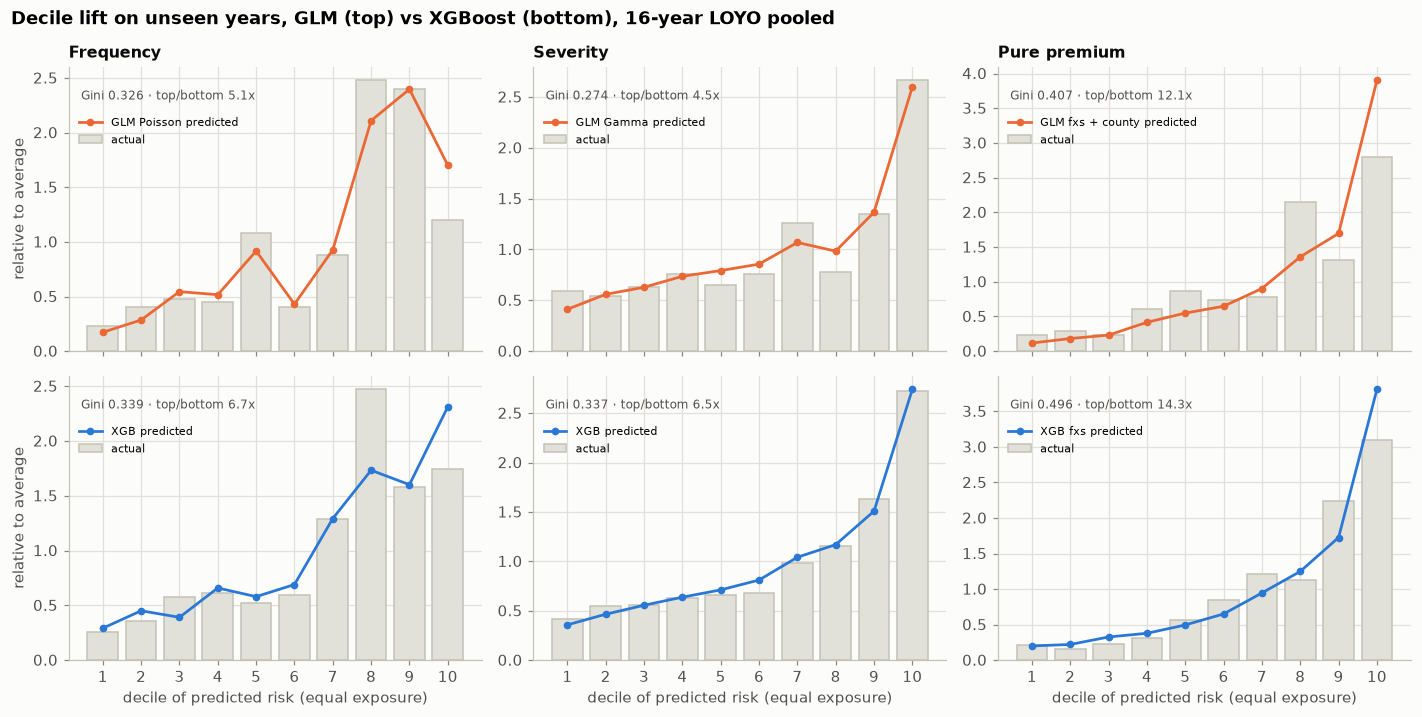

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.6), sharex=True)
for j, (k, (act, models)) in enumerate(LIFT_SETS.items()):
    for i, m in enumerate(models):
        ax, t = axes[i, j], LIFTS[(k, m)]
        xs = t.index.to_numpy()
        ax.bar(xs, t.actual_rel, color=GRID, edgecolor=AXIS, width=0.8, label="actual")
        c = ORANGE if i == 0 else BLUE
        ax.plot(xs, t.pred_rel, color=c, marker="o", ms=4, lw=1.8, label=f"{m} predicted")
        r = LIFT_TBL.query("kind == @k and model == @m").iloc[0]
        ax.text(0.03, 0.92, f"Gini {r.pooled_gini:.3f} · top/bottom {r.top_over_bottom_actual:.1f}x",
                transform=ax.transAxes, fontsize=8, color=INK_2, va="top")
        ax.legend(loc="upper left", bbox_to_anchor=(0, 0.86), fontsize=7.5)
        if j == 0:
            ax.set_ylabel("relative to average")
        if i == 0:
            ax.set_title(KIND_LABEL[k].split(" (")[0], fontsize=10.5)
        ax.set_xticks(xs)
for ax in axes[1]:
    ax.set_xlabel("decile of predicted risk (equal exposure)")
fig.suptitle("Decile lift on unseen years, GLM (top) vs XGBoost (bottom), 16-year LOYO pooled",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "lift_charts")
plt.show()

saved reports\figures\09_double_lift.png


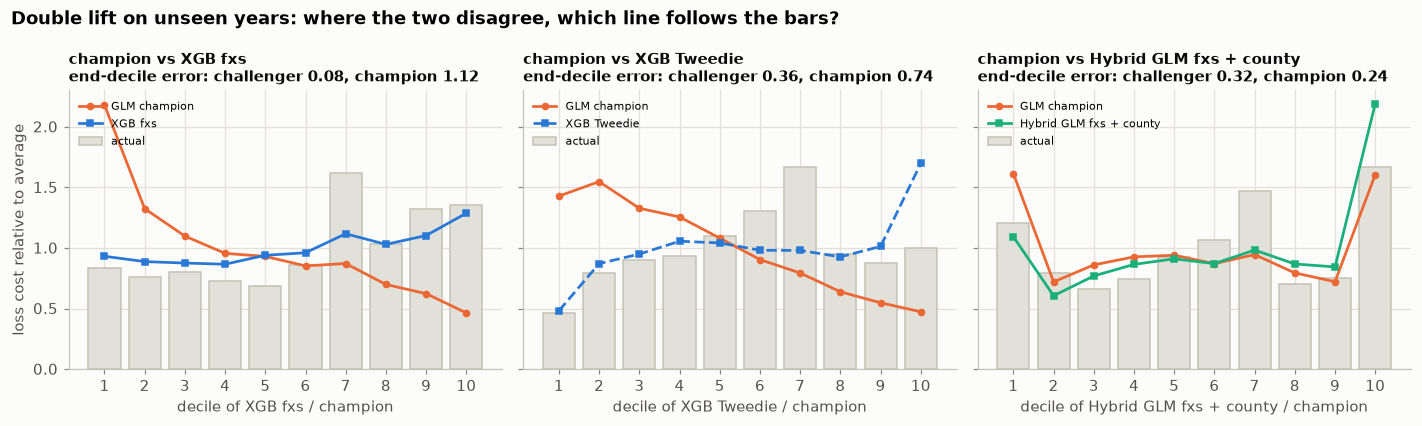

,challenger,end_decile_error_challenger,end_decile_error_champion,low_end_actual,low_end_challenger,low_end_champion,high_end_actual,high_end_challenger,high_end_champion
0,XGB fxs,0.08,1.12,0.83,0.93,2.18,1.36,1.29,0.46
1,XGB Tweedie,0.36,0.74,0.46,0.48,1.43,1.00,1.70,0.47
2,Hybrid GLM fxs + county,0.32,0.24,1.21,1.09,1.61,1.67,2.19,1.61


In [12]:
DLS, dl_rows = {}, []
for b in ("XGB fxs", "XGB Tweedie", HYB):
    rba, rbb = C.rebase_by_year(po, CHAMP, X.LOSS), C.rebase_by_year(po, b, X.LOSS)
    dl = pp.double_lift(po[X.LOSS], rbb, rba, po["exposure"])       # a = challenger, b = champion
    DLS[b] = dl
    e = C.end_decile_error(dl)
    dl_rows.append({"challenger": b, "end_decile_error_challenger": e["a"], "end_decile_error_champion": e["b"],
                    "low_end_actual": dl.losses_relative.iloc[0], "low_end_challenger": dl.a_relative.iloc[0], "low_end_champion": dl.b_relative.iloc[0],
                    "high_end_actual": dl.losses_relative.iloc[-1], "high_end_challenger": dl.a_relative.iloc[-1], "high_end_champion": dl.b_relative.iloc[-1]})
DL_TBL = pd.DataFrame(dl_rows)
DL_TBL.to_csv(REP / "08_double_lift.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, (b, dl) in zip(axes, DLS.items()):
    xs = dl.index.to_numpy()
    ax.bar(xs, dl.losses_relative, color=GRID, edgecolor=AXIS, width=0.8, label="actual")
    ax.plot(xs, dl.b_relative, color=ORANGE, marker="o", ms=4, lw=1.8, label="GLM champion")
    ax.plot(xs, dl.a_relative, color=PP_COL[b] if b != "XGB Tweedie" else BLUE, marker="s", ms=4, lw=1.8, label=b,
            ls="-" if b != "XGB Tweedie" else "--")
    r = DL_TBL.set_index("challenger").loc[b]
    ax.set_title(f"champion vs {b}\nend-decile error: challenger {r.end_decile_error_challenger:.2f}, champion {r.end_decile_error_champion:.2f}",
                 fontsize=9.5)
    ax.set_xticks(xs)
    ax.set_xlabel(f"decile of {b} / champion")
    ax.legend(fontsize=7.5, loc="upper left")
axes[0].set_ylabel("loss cost relative to average")
fig.suptitle("Double lift on unseen years: where the two disagree, which line follows the bars?",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "double_lift")
plt.show()
DL_TBL.round(2)

**Result: ranking.**
- **Pooled Gini:** XGBoost ranks better in every model: frequency 0.339 vs 0.326, severity 0.337 vs 0.274, pure premium 0.496 vs 0.407.
- **The double lift (left panel) is the most striking chart in this notebook.**
  - It sorts cells by how much XGBoost freq × sev disagrees with the champion.
  - In the decile where the champion is relatively *highest*, it predicts 2.18× average, XGBoost 0.93×, and **actual is 0.83×**.
  - Where the champion is relatively *lowest*, it predicts 0.46×, XGBoost 1.29×, and **actual is 1.36×**.
  - End-decile error: **champion 1.12, XGBoost 0.08**. Where they disagree, XGBoost is right.
- **Against the XGBoost Tweedie** the champion also loses (0.74 vs 0.36). That reverses Milestone 10's result between the two XGBoost structures. The Tweedie still fails the segment checks, though.
- **Hybrid vs champion: mixed.** End-decile error 0.32 vs 0.24, a slight win for the champion. The hybrid fixes the low end (actual 1.21: hybrid 1.09, champion 1.61) but over-shoots the high end (actual 1.67: hybrid 2.19, champion 1.61).

## 4. Is the difference real?
Three views, from simplest to most careful:
1. **Per-year wins:** in how many of the 16 unseen years does the challenger beat the GLM? A **sign test** asks how surprising that count would be if the two models were really equal (like 16 fair coin flips).
2. **Year bootstrap:** resample the 16 per-year differences with replacement 10,000 times. The middle 95% of the resampled means is the confidence interval (CI). This asks: "with a different draw of weather years, would the gap survive?"
3. **Cluster bootstrap:** inside each unseen year, resample county groups with replacement 1,000 times and rescore both models. This measures how much of the gap is within-year sampling noise. Counties are resampled as whole groups because claims in the same storm and place move together.

In [13]:
s = SC["loyo16"]
PAIRS = [("frequency", "GLM Poisson", "XGB"), ("frequency", "GLM Poisson", "GLM NB"), ("frequency", "GLM Poisson", "Hybrid GLM"),
         ("severity", "GLM Gamma", "XGB"), ("severity", "GLM Gamma", "XGB no-geo"), ("severity", "GLM Gamma", "Hybrid GLM"),
         ("pure_premium", CHAMP, "XGB fxs"), ("pure_premium", CHAMP, "XGB Tweedie"),
         ("pure_premium", CHAMP, "XGB fxs no-geo + county"), ("pure_premium", CHAMP, HYB)]
rows = []
for k, a, b in PAIRS:
    w = C.wins_vs(s, k, a, b)
    yb = C.year_bootstrap(s, k, a, b)
    yg = C.year_bootstrap(s, k, a, b, metric="gini")
    rows.append({"kind": k, "baseline": a, "challenger": b, "years_won": f"{w['b_wins']}/{w['years']}",
                 "sign_test_p": w["sign_test_p"], "diff_pts": yb["estimate"], "year_boot_CI": f"{yb['ci_low']:.2f} to {yb['ci_high']:.2f}",
                 "dev_ci_low": yb["ci_low"], "dev_ci_high": yb["ci_high"],
                 "gini_diff": yg["estimate"], "gini_year_boot_CI": f"{yg['ci_low']:.3f} to {yg['ci_high']:.3f}",
                 "gini_ci_low": yg["ci_low"], "gini_ci_high": yg["ci_high"]})
REAL = pd.DataFrame(rows)
REAL.round(4).to_csv(REP / "08_significance_year_bootstrap.csv", index=False)
REAL[["kind", "baseline", "challenger", "years_won", "sign_test_p", "diff_pts", "year_boot_CI", "gini_diff", "gini_year_boot_CI"]].round(4)

,kind,baseline,challenger,years_won,sign_test_p,diff_pts,year_boot_CI,gini_diff,gini_year_boot_CI
0,frequency,GLM Poisson,XGB,14/16,0.0042,1.7902,0.08 to 3.24,0.0512,0.022 to 0.078
1,frequency,GLM Poisson,GLM NB,12/16,0.0768,0.4657,-0.42 to 1.26,0.0020,-0.010 to 0.014
2,frequency,GLM Poisson,Hybrid GLM,9/16,0.8036,0.0401,-0.16 to 0.22,-0.0034,-0.008 to 0.001
3,severity,GLM Gamma,XGB,16/16,0.0000,7.2202,5.39 to 9.12,0.0555,0.035 to 0.079
4,severity,GLM Gamma,XGB no-geo,14/16,0.0042,4.9696,2.98 to 7.05,0.0365,0.017 to 0.059
5,severity,GLM Gamma,Hybrid GLM,15/16,0.0005,1.5308,0.53 to 2.53,-0.0017,-0.010 to 0.005
6,pure_premium,GLM fxs + county,XGB fxs,15/16,0.0005,4.2664,2.86 to 5.74,0.0604,0.041 to 0.080
7,pure_premium,GLM fxs + county,XGB Tweedie,15/16,0.0005,7.5580,4.83 to 10.11,0.1230,0.077 to 0.167
8,pure_premium,GLM fxs + county,XGB fxs no-geo + county,14/16,0.0042,2.5674,1.48 to 3.69,0.0390,0.023 to 0.055
9,pure_premium,GLM fxs + county,Hybrid GLM fxs + county,9/16,0.8036,0.4303,-0.29 to 1.13,0.0082,0.000 to 0.017


saved reports\figures\09_per_year_wins.png


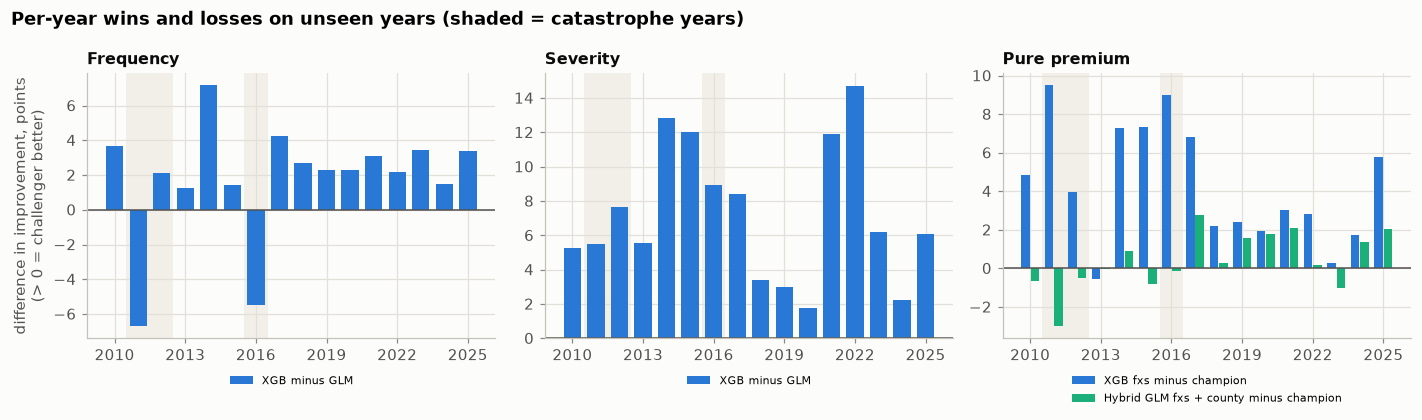

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharex=True)
for ax, (k, a, bs) in zip(axes, (("frequency", "GLM Poisson", ["XGB"]), ("severity", "GLM Gamma", ["XGB"]),
                                 ("pure_premium", CHAMP, ["XGB fxs", HYB]))):
    for cy in val.CAT_YEARS:
        ax.axvspan(cy - 0.5, cy + 0.5, color=CAT_SHADE, zorder=0, lw=0)
    pa = s.query("kind == @k and model == @a").set_index("test_year")["improvement_rebased_pct"]
    wdt = 0.8 / len(bs)
    for i, b in enumerate(bs):
        d = (s.query("kind == @k and model == @b").set_index("test_year")["improvement_rebased_pct"] - pa).reindex(yrs)
        c = BLUE if b.startswith("XGB") else AQUA
        ax.bar(yrs + (i - (len(bs) - 1) / 2) * wdt, d, width=wdt * 0.92, color=c, label=f"{b} minus {'champion' if k == 'pure_premium' else 'GLM'}")
    ax.axhline(0, color=INK_2, lw=1)
    ax.set_title(KIND_LABEL[k].split(" (")[0], fontsize=10.5)
    ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=1)
    ax.set_xticks([2010, 2013, 2016, 2019, 2022, 2025])
axes[0].set_ylabel("difference in improvement, points\n(> 0 = challenger better)")
fig.suptitle("Per-year wins and losses on unseen years (shaded = catastrophe years)", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "per_year_wins")
plt.show()

In [15]:
# Cluster bootstrap (county groups within each unseen year), 16-year LOYO and the holdout (clusters = county group x year).
CB_PAIRS = {"frequency": ("GLM Poisson", ["XGB", "Hybrid GLM"]), "severity": ("GLM Gamma", ["XGB", "Hybrid GLM"]),
            "pure_premium": (CHAMP, ["XGB fxs", "XGB Tweedie", HYB])}
cb_rows = []
for design in ("loyo16", "holdout"):
    for k, (a, bs) in CB_PAIRS.items():
        o = OOF[(k, design)].copy()
        if design == "holdout":
            o["cluster"] = o["county_group"].astype(str) + "|" + o["year"].astype(str)
            o["grp"] = 0
        else:
            o["cluster"], o["grp"] = o["county_group"].astype(str), o["year"]
        res = C.cluster_bootstrap(o, k, [a] + bs, B=1000, cluster="cluster", group="grp")
        for b in bs:
            for metric in ("improvement", "gini"):
                r = C.bootstrap_diff(res, a, b, metric)
                cb_rows.append({"design": design, "kind": k, **r})
CB = pd.DataFrame(cb_rows)
CB.round(4).to_csv(REP / "08_significance_cluster_bootstrap.csv", index=False)
CB.round(3)

,design,kind,a,b,metric,ci_low,ci_high,share_reps_positive,boot_mean
0,loyo16,frequency,GLM Poisson,XGB,improvement,1.059,2.707,1.000,1.861
1,loyo16,frequency,GLM Poisson,XGB,gini,0.028,0.074,1.000,0.051
2,loyo16,frequency,GLM Poisson,Hybrid GLM,improvement,-0.089,0.180,0.723,0.040
3,loyo16,frequency,GLM Poisson,Hybrid GLM,gini,-0.009,0.002,0.115,-0.003
4,loyo16,severity,GLM Gamma,XGB,improvement,3.659,8.748,1.000,6.320
5,loyo16,severity,GLM Gamma,XGB,gini,0.032,0.068,1.000,0.049
6,loyo16,severity,GLM Gamma,Hybrid GLM,improvement,0.610,2.384,0.999,1.523
7,loyo16,severity,GLM Gamma,Hybrid GLM,gini,-0.007,0.008,0.458,-0.000
8,loyo16,pure_premium,GLM fxs + county,XGB fxs,improvement,2.996,5.464,1.000,4.166
9,loyo16,pure_premium,GLM fxs + county,XGB fxs,gini,0.039,0.081,1.000,0.060


saved reports\figures\09_bootstrap_ci.png


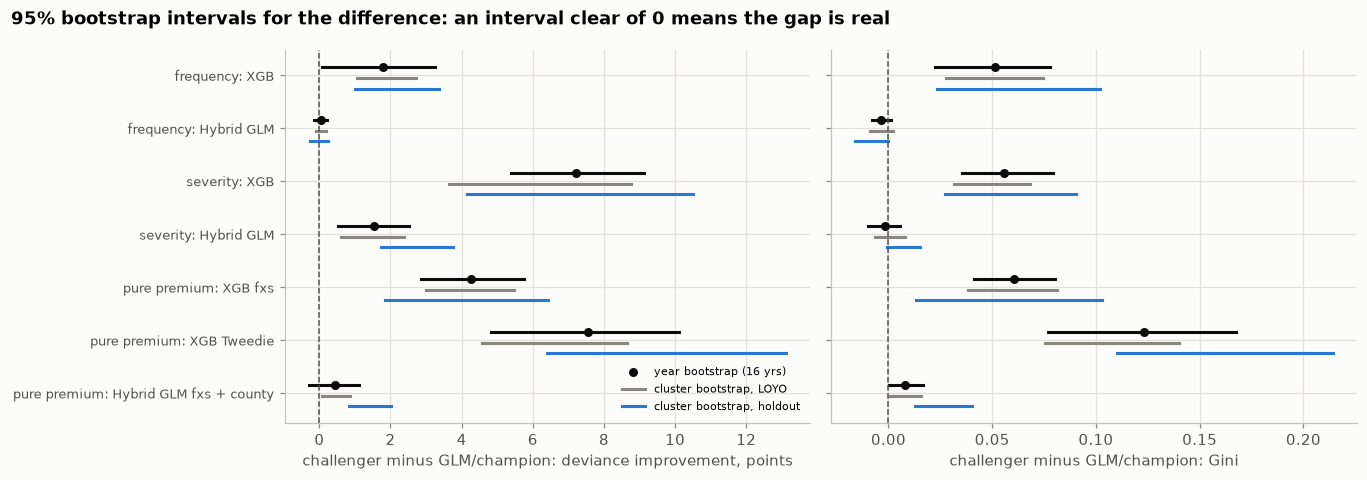

In [16]:
yb = REAL.set_index(["kind", "challenger"])
items = [("frequency", "XGB"), ("frequency", "Hybrid GLM"), ("severity", "XGB"), ("severity", "Hybrid GLM"),
         ("pure_premium", "XGB fxs"), ("pure_premium", "XGB Tweedie"), ("pure_premium", HYB)]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
for ax, metric, ycol in ((axes[0], "improvement", ("dev_ci_low", "dev_ci_high", "diff_pts")),
                         (axes[1], "gini", ("gini_ci_low", "gini_ci_high", "gini_diff"))):
    for i, (k, b) in enumerate(items):
        y = len(items) - 1 - i
        r = yb.loc[(k, b)]
        ax.plot([r[ycol[0]], r[ycol[1]]], [y + 0.15] * 2, color=INK, lw=2)
        ax.scatter(r[ycol[2]], y + 0.15, color=INK, s=24, zorder=3, label="year bootstrap (16 yrs)" if i == 0 else None)
        for design, dy, c, lab in (("loyo16", -0.05, MUTED, "cluster bootstrap, LOYO"), ("holdout", -0.25, BLUE, "cluster bootstrap, holdout")):
            q = CB.query("design == @design and kind == @k and b == @b and metric == @metric")
            if len(q):
                q = q.iloc[0]
                ax.plot([q.ci_low, q.ci_high], [y + dy] * 2, color=c, lw=2, label=lab if i == 0 else None)
    ax.axvline(0, color=INK_2, lw=1, ls="--")
    ax.set_yticks(range(len(items)), [f"{k.replace('_', ' ')}: {b}" for k, b in items][::-1], fontsize=8.5)
    ax.set_xlabel("challenger minus GLM/champion: " + ("deviance improvement, points" if metric == "improvement" else "Gini"))
axes[0].legend(fontsize=7.5, loc="lower right")
fig.suptitle("95% bootstrap intervals for the difference: an interval clear of 0 means the gap is real",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "bootstrap_ci")
plt.show()

**Result: is the gap real?**
- **XGBoost vs the GLMs: yes, by every test.**
  - Pure premium (freq × sev): +4.3 points, year-bootstrap CI **2.9 to 5.7**, 15 of 16 years (sign test p = 0.0005). The cluster bootstrap agrees on 16-year LOYO (3.0 to 5.5) and on the holdout (1.9 to 6.4).
  - Severity: +7.2, CI 5.4 to 9.1, 16 of 16 years.
  - Frequency: +1.8, CI 0.1 to 3.2, 14 of 16 years. It's real but the smallest gap, and the two years it loses are the two biggest storms (2011, 2016).
- **The negative binomial isn't really better** than the Poisson: +0.5, CI −0.4 to 1.3.
- **The hybrid's gain is small and not consistent across years.**
  - Pure premium: +0.4 points, year-bootstrap CI −0.3 to 1.1, better in only 9 of 16 years. Within years, though, it's clear of noise (cluster CI 0.07 to 0.87 on LOYO; 0.8 to 2.0 on the holdout).
  - Severity: the hybrid's improvement is solid (+1.5, CI 0.5 to 2.5, 15 of 16 years).
  - Frequency: the hybrid's year built × zone term adds essentially nothing out of sample (+0.04, CI −0.16 to 0.22).

## 5. Beyond accuracy
### 5a. Stability: do predictions for the same cells move when the training data changes?
All models score the same fixed grid: the 2025 in-force cells, weighted by exposure. The change is measured **level-free**: each prediction is divided by its own exposure-weighted average first, so a model whose *overall* level moves (dropping 2016 lowers every rate) isn't penalised for that. We compare the all-years model with:
- each of the 16 leave-one-year-out models (one fewer year);
- the 2010–2020 model (five fewer years);
- for XGBoost, the same data with only the random seed changed.

In [17]:
wgt = GRID_CELLS["exposure"].to_numpy(float)
ref = GR[GR.split == "all"].set_index(["model", "cell"])["rate"]
def shift(split, model):
    g = GR[(GR.split == split) & (GR.model == model)].set_index("cell")["rate"].sort_index()
    return C.relative_shift(g.to_numpy(), ref.loc[model].sort_index().to_numpy(), wgt)
STAB_MODELS = ["freq/GLM Poisson", "freq/Hybrid GLM", "freq/XGB", "sev/GLM Gamma", "sev/Hybrid GLM", "sev/XGB",
               "pp/GLM fxs", "pp/" + CHAMP, "pp/" + HYB, "pp/XGB fxs", "pp/XGB Tweedie"]
rows = []
for m in STAB_MODELS:
    loyo = [shift(f"loyo16:{y}", m) for y in val.ALL_YEARS]
    r = {"model": m, "drop one year: mean %": np.mean([d["mean_pct"] for d in loyo]),
         "drop one year: worst fold mean %": max(d["mean_pct"] for d in loyo),
         "worst fold": val.ALL_YEARS[int(np.argmax([d["mean_pct"] for d in loyo]))],
         "drop 2016: mean %": shift("loyo16:2016", m)["mean_pct"], "drop 2016: P95 %": shift("loyo16:2016", m)["p95_pct"],
         "5 fewer years (2010-20): mean %": shift("holdout:holdout", m)["mean_pct"],
         "5 fewer years: P95 %": shift("holdout:holdout", m)["p95_pct"]}
    if "XGB" in m:
        sd = [shift(f"seed:{k}", m) for k in (1, 2, 3)]
        r["seed only: mean %"], r["seed only: P95 %"] = np.mean([d["mean_pct"] for d in sd]), np.mean([d["p95_pct"] for d in sd])
    else:
        r["seed only: mean %"], r["seed only: P95 %"] = 0.0, 0.0
    rows.append(r)
STAB = pd.DataFrame(rows).set_index("model")
STAB.round(2).to_csv(REP / "08_stability.csv")
STAB.round(2)

,drop one year: mean %,drop one year: worst fold mean %,worst fold,drop 2016: mean %,drop 2016: P95 %,5 fewer years (2010-20): mean %,5 fewer years: P95 %,seed only: mean %,seed only: P95 %
model,,,,,,,,,
freq/GLM Poisson,2.66,13.92,2011,8.76,19.91,2.30,6.42,0.00,0.00
freq/Hybrid GLM,3.04,16.64,2011,9.66,16.35,2.26,5.66,0.00,0.00
freq/XGB,4.40,17.72,2016,17.72,46.37,3.60,10.56,1.72,4.62
sev/GLM Gamma,1.99,7.46,2016,7.46,18.57,2.43,4.74,0.00,0.00
sev/Hybrid GLM,2.16,8.21,2016,8.21,20.47,2.57,4.97,0.00,0.00
sev/XGB,4.27,14.66,2011,11.62,43.42,4.24,12.38,1.84,4.92
pp/GLM fxs,3.56,17.54,2011,14.58,35.29,3.81,10.60,0.00,0.00
pp/GLM fxs + county,6.37,42.03,2011,29.79,85.48,4.28,11.01,0.00,0.00
pp/Hybrid GLM fxs + county,6.79,44.38,2011,30.52,88.61,4.18,10.91,0.00,0.00


saved reports\figures\09_stability.png


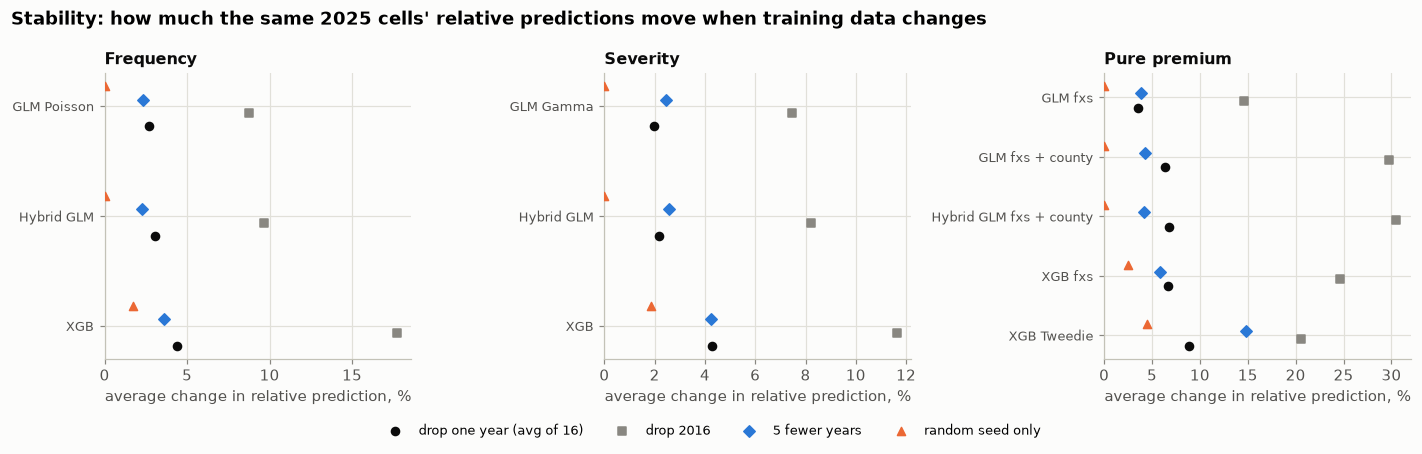

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=False)
groups = {"Frequency": ["freq/GLM Poisson", "freq/Hybrid GLM", "freq/XGB"], "Severity": ["sev/GLM Gamma", "sev/Hybrid GLM", "sev/XGB"],
          "Pure premium": ["pp/GLM fxs", "pp/" + CHAMP, "pp/" + HYB, "pp/XGB fxs", "pp/XGB Tweedie"]}
cols = [("drop one year: mean %", "drop one year (avg of 16)", "o", INK), ("drop 2016: mean %", "drop 2016", "s", MUTED),
        ("5 fewer years (2010-20): mean %", "5 fewer years", "D", BLUE), ("seed only: mean %", "random seed only", "^", ORANGE)]
for ax, (title, ms) in zip(axes, groups.items()):
    t = STAB.loc[ms]
    y = np.arange(len(ms))[::-1]
    for i, (c, lab, mk, colr) in enumerate(cols):
        ax.scatter(t[c], y + (i - 1.5) * 0.12, marker=mk, color=colr, s=28, label=lab, zorder=3)
    ax.set_yticks(y, [m.split("/", 1)[1] for m in ms], fontsize=8.5)
    ax.set_xlim(left=0)
    ax.set_title(title, fontsize=10.5)
    ax.set_xlabel("average change in relative prediction, %")
fig.legend(*axes[2].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=8.5, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("Stability: how much the same 2025 cells' relative predictions move when training data changes",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "stability")
plt.show()

**Result: stability.**
- **The GLMs move least for frequency and severity** (about 2–3% on average when one year is dropped). XGBoost moves about twice as much (4.3–4.4%).
- **XGBoost's predictions also move 1.7–4.5% when nothing changes but the random seed**, because it samples rows and columns at random while it builds trees. A rate that changes on a re-run with identical data is hard to defend.
- **Dropping a hurricane year moves every model most.**
  - Dropping 2016 moves XGBoost frequency 17.7% (GLM 8.8%).
  - Dropping 2011 moves the champion's pure premium **42%**, against 17.5% for the GLM without the county factor. The county factor is the least stable part of the champion: one storm changes which counties look expensive.
- **XGBoost Tweedie:** five fewer years (2010–2020 vs 2010–2025) move it the most (14.8% average, P95 53%).

### 5b. Catastrophe behaviour: which model is less wrong in the worst years?
In 2011 (Irene), 2012 (Sandy) and 2016 (Matthew), every model's raw A/E is far above 1, because none predicted the storm. The fair question is whether the model put the storm's losses in the right cells: the re-based improvement in that year. We also check where they went (Tidewater vs inland, A/V vs B/C/X).

In [19]:
cat = s[s.cat_year].pivot_table(index=["kind", "model"], columns="test_year", values="improvement_rebased_pct")
cat["mean"] = cat.mean(axis=1)
cat_raw = s[s.cat_year & (s.kind == "pure_premium")].pivot_table(index="model", columns="test_year", values="actual_over_expected")
CAT = cat.round(2)
CAT.to_csv(REP / "08_cat_years.csv")
po_cat = po[po.year.isin(val.CAT_YEARS)]
cat_seg = C.segment_ae(po_cat, [CHAMP, HYB, "XGB fxs", "XGB Tweedie"], ["coastal_tidal", "flood_zone_group"], X.LOSS)
print("Re-based improvement in the catastrophe years (%):"); print(CAT.to_string())
print("\nRaw A/E, pure premium:"); print(cat_raw.round(2).to_string())
print("\nCat-year segment A/E (re-based within each cat year):")
print(cat_seg.pivot_table(index=["feature", "level"], columns="model", values="ae").round(2).to_string())

Re-based improvement in the catastrophe years (%):
test_year                              2011   2012   2016   mean
kind         model                                              
frequency    GLM NB                   15.96  12.50   9.58  12.68
             GLM Poisson              17.76  16.28   8.44  14.16
             Hybrid GLM               16.73  16.20   8.50  13.81
             XGB                      11.05  18.40   2.99  10.82
pure_premium GLM Tweedie               6.27  14.82   9.27  10.12
             GLM fxs                  15.19  19.82  11.03  15.35
             GLM fxs + county          0.04  21.48   3.32   8.28
             Hybrid GLM fxs + county  -2.96  20.99   3.18   7.07
             XGB Tweedie               8.95  16.24   6.01  10.40
             XGB fxs                   9.54  25.43  12.30  15.76
             XGB fxs no-geo + county  -0.24  24.42   3.70   9.30
severity     GLM Gamma                 0.83  16.41  12.08   9.77
             Hybrid GLM                

saved reports\figures\09_cat_years.png


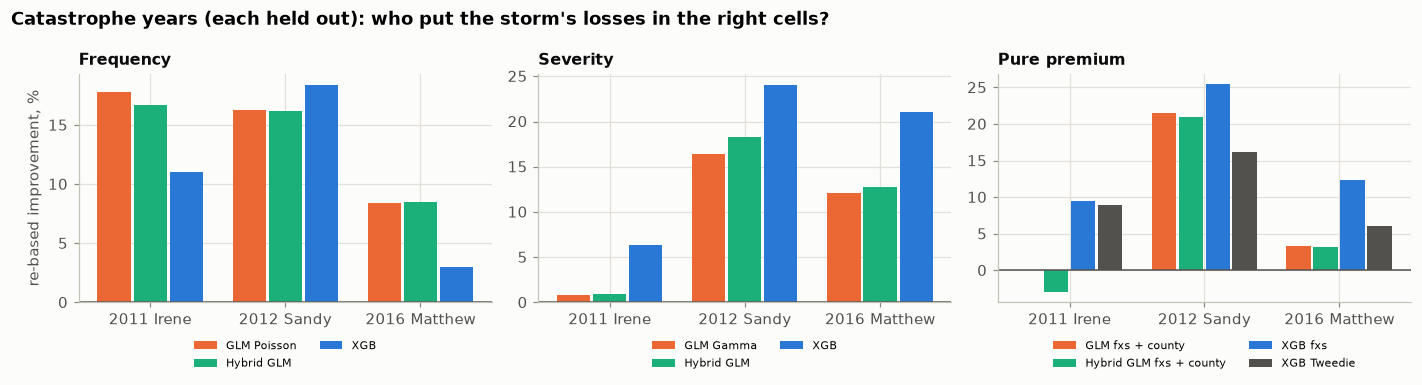

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
for ax, (k, models) in zip(axes, (("frequency", ["GLM Poisson", "Hybrid GLM", "XGB"]), ("severity", ["GLM Gamma", "Hybrid GLM", "XGB"]),
                                  ("pure_premium", [CHAMP, HYB, "XGB fxs", "XGB Tweedie"]))):
    x = np.arange(3)
    wd = 0.8 / len(models)
    for i, m in enumerate(models):
        v = cat.loc[(k, m), list(val.CAT_YEARS)].to_numpy()
        c = {"GLM Poisson": ORANGE, "GLM Gamma": ORANGE, "Hybrid GLM": AQUA, "XGB": BLUE}.get(m, PP_COL.get(m))
        ax.bar(x + (i - (len(models) - 1) / 2) * wd, v, width=wd * 0.92, color=c, label=m)
    ax.set_xticks(x, ["2011 Irene", "2012 Sandy", "2016 Matthew"])
    ax.axhline(0, color=INK_2, lw=1)
    ax.set_title(KIND_LABEL[k].split(" (")[0], fontsize=10.5)
    ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
axes[0].set_ylabel("re-based improvement, %")
fig.suptitle("Catastrophe years (each held out): who put the storm's losses in the right cells?",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "cat_years")
plt.show()

**Result: catastrophe years.**
- **No model forecasts the storm:** raw pure-premium A/E is 3.3–3.6 in 2011, 1.7–1.8 in 2012 and 7.8–8.1 in 2016.
- **Placing the losses in the right cells:**
  - XGBoost freq × sev is best on average (15.8%), ahead of the champion (8.3%) and the hybrid (7.1%).
  - The plain GLM *without* the county factor scores 15.3%: in a held-out hurricane year, the county factor (learned from other storms) **points the wrong way**. Milestone 9 found the same.
  - For **frequency**, the GLM is better in 2011 and 2016 (17.8% and 8.4% vs 11.1% and 3.0%). XGBoost's extra frequency detail is tuned to normal years.
- **Where the losses went:** every model under-predicts Tidewater in cat years (A/E 1.20–1.47) and over-predicts inland (0.08–0.13). Hurricanes concentrate losses on the coast more than an average year does.

### 5c. Explainability: what can each model tell a customer or a regulator?
A GLM has one multiplier per level, so "your area's cost is 3.5× the base because buildings from the 1960s–70s claim more often and claim bigger" comes straight out of the relativity table. XGBoost's answer depends on every other feature of the cell. Below, we flip one feature at a time on every 2025 cell and check whether the model ever moves the **wrong way**: elevation, a lower-risk zone or post-FIRM construction *raising* expected losses, or higher coverage *lowering* claim size. A regulator would ask about exactly these.

In [21]:
def flip(df, f, frm, to):
    sub = df[df[f].astype(str) == frm].copy()
    out = sub.copy()
    out[f] = to
    return sub, out

CHECKS = [("frequency", "elevated", "False", "True", "up is wrong"), ("frequency", "flood_zone_group", "A/V high risk", "B/C/X moderate-low risk", "up is wrong"),
          ("frequency", "post_firm", "False", "True", "up is wrong"),
          ("severity", "elevated", "False", "True", "up is wrong"), ("severity", "flood_zone_group", "A/V high risk", "B/C/X moderate-low risk", "up is wrong"),
          ("severity", "building_coverage_band", "under $100K", "$100K-$249K", "down is wrong"),
          ("severity", "building_coverage_band", "$100K-$249K", "$250K or more", "down is wrong"),
          ("pure_premium", "elevated", "False", "True", "up is wrong"), ("pure_premium", "flood_zone_group", "A/V high risk", "B/C/X moderate-low risk", "up is wrong"),
          ("pure_premium", "building_coverage_band", "$100K-$249K", "$250K or more", "down is wrong")]
MODELS_X = {"frequency": {"GLM": "freq/GLM Poisson", "Hybrid GLM": "freq/Hybrid GLM", "XGB": "freq/XGB"},
            "severity": {"GLM": "sev/GLM Gamma", "Hybrid GLM": "sev/Hybrid GLM", "XGB": "sev/XGB"},
            "pure_premium": {"GLM": "pp/" + CHAMP, "Hybrid GLM": "pp/" + HYB, "XGB fxs": "pp/XGB fxs", "XGB Tweedie": "pp/XGB Tweedie"}}
RATE = {"frequency": C.freq_rate, "severity": C.sev_rate, "pure_premium": C.pp_rate}
rows = []
for k, f, frm, to, rule in CHECKS:
    a, b = flip(GRID_CELLS, f, frm, to)
    w = a["exposure"].to_numpy(float)
    for lab, key in MODELS_X[k].items():
        r = RATE[k](ALL[key], b) / RATE[k](ALL[key], a)
        wrong = (r > 1 + 1e-9) if rule == "up is wrong" else (r < 1 - 1e-9)
        rows.append({"model kind": k, "change": f"{LABELS[f]}: {frm} -> {to}", "model": lab,
                     "average effect": float(np.exp(np.average(np.log(r), weights=w))),
                     "min effect": float(r.min()), "max effect": float(r.max()),
                     "% of exposure moving the wrong way": float(100 * w[wrong].sum() / w.sum())})
DIRS = pd.DataFrame(rows)
DIRS.round(3).to_csv(REP / "08_direction_checks.csv", index=False)
DIRS.pivot_table(index=["model kind", "change"], columns="model", values=["average effect", "% of exposure moving the wrong way"], sort=False).round(2)

average effect                                      % of exposure moving the wrong way                                      
model                                                                        GLM Hybrid GLM   XGB XGB fxs XGB Tweedie                                GLM Hybrid GLM    XGB XGB fxs XGB Tweedie
model kind   change                                                                                                                                                                           
frequency    Elevated: False -> True                                        1.00       1.00  1.03     NaN         NaN                                0.0        0.0  77.84     NaN         NaN
             Flood zone: A/V high risk -> B/C/X moderate-low risk           0.46       0.48  0.54     NaN         NaN                                0.0        0.0   2.22     NaN         NaN
             Post-FIRM: False -> True                                       1.00       1.00  0.89     NaN         NaN                                0.0        0.0  14.82     NaN         NaN
severity     Elevated: False -> True                                        0.76       0.80  0.81     NaN         NaN                                0.0        0.0  21.76     NaN         NaN
             Flood zone: A/V high risk -> B/C/X moderate-low risk           0.75       0.78  0.77     NaN         NaN                                0.0        0.0  12.51     NaN         NaN
             Building coverage: under $100K -> $100K-$249K                  1.23       1.21  1.25     NaN         NaN                                0.0        0.0   7.38     NaN         NaN
             Building coverage: $100K-$249K -> $250K or more                1.17       1.14  1.13     NaN         NaN                                0.0        0.0  21.91     NaN         NaN
pure_premium Elevated: False -> True                                        0.76       0.80   NaN    0.83        0.96                                0.0        0.0    NaN   29.60         0.0
             Flood zone: A/V high risk -> B/C/X moderate-low risk           0.34       0.38   NaN    0.42        0.51                                0.0        0.0    NaN    1.59         0.0
             Building coverage: $100K-$249K -> $250K or more                1.17       1.14   NaN    1.07        1.03                                0.0        0.0    NaN   34.40         0.0

In [22]:
def n_leaves(m):
    t = m.booster.trees_to_dataframe()
    return int((t.Feature == "Leaf").sum()), int(t.Tree.nunique())
cmplx = []
for lab, key in (("Frequency GLM", "freq/GLM Poisson"), ("Frequency hybrid GLM", "freq/Hybrid GLM"),
                 ("Severity GLM", "sev/GLM Gamma"), ("Severity hybrid GLM", "sev/Hybrid GLM")):
    p = ALL[key].params
    cmplx.append({"model": lab, "numbers to read": int(sum(1 for c in p.index if not c.startswith("year[") and c != "const")),
                  "form": "one multiplier per level (+ 2-way table for interactions)"})
for lab, key in (("Frequency XGB", "freq/XGB"), ("Severity XGB", "sev/XGB"), ("Tweedie XGB", "pp/XGB Tweedie")):
    lv, tr = n_leaves(ALL[key])
    cmplx.append({"model": lab, "numbers to read": lv, "form": f"{tr} trees; a cell's prediction adds one leaf from every tree"})
pd.DataFrame(cmplx)

,model,numbers to read,form
0,Frequency GLM,6,one multiplier per level (+ 2-way table for interactions)
1,Frequency hybrid GLM,9,one multiplier per level (+ 2-way table for interactions)
2,Severity GLM,13,one multiplier per level (+ 2-way table for interactions)
3,Severity hybrid GLM,20,one multiplier per level (+ 2-way table for interactions)
4,Frequency XGB,5315,170 trees; a cell's prediction adds one leaf from every ...
5,Severity XGB,13603,940 trees; a cell's prediction adds one leaf from every ...
6,Tweedie XGB,3061,120 trees; a cell's prediction adds one leaf from every ...


In [23]:
EXPL = pd.DataFrame([
    ("Relativity table a customer can read", "yes: one number per level", "yes: plus a small 2-way table per interaction", "no: needs SHAP or partial-dependence summaries (Milestone 12)"),
    ("Rating worksheet (show the arithmetic)", "yes, exact", "yes, exact", "no exact worksheet; only approximate attributions"),
    ("Effect directions guaranteed", "yes: one sign per factor, inspectable", "yes, after checking the interaction cells", "only where monotone constraints are set (Tweedie only)"),
    ("Same effect everywhere", "yes (multiplicative)", "yes, except the stated interactions", "no: an effect can differ in every cell"),
    ("Regulator / rate filing", "standard exhibit (relativities + CIs)", "standard, with interaction exhibits", "possible but needs model governance docs, SHAP, stability evidence"),
    ("Stable when retrained", "deterministic", "deterministic", "moves with the random seed, too"),
], columns=["question", "GLM champion", "Hybrid GLM", "XGBoost"])
EXPL.to_csv(REP / "08_explainability.csv", index=False)
EXPL

,question,GLM champion,Hybrid GLM,XGBoost
0,Relativity table a customer can read,yes: one number per level,yes: plus a small 2-way table per interaction,no: needs SHAP or partial-dependence summaries (Mileston...
1,Rating worksheet (show the arithmetic),"yes, exact","yes, exact",no exact worksheet; only approximate attributions
2,Effect directions guaranteed,"yes: one sign per factor, inspectable","yes, after checking the interaction cells",only where monotone constraints are set (Tweedie only)
3,Same effect everywhere,yes (multiplicative),"yes, except the stated interactions",no: an effect can differ in every cell
4,Regulator / rate filing,standard exhibit (relativities + CIs),"standard, with interaction exhibits","possible but needs model governance docs, SHAP, stabilit..."
5,Stable when retrained,deterministic,deterministic,"moves with the random seed, too"


**Result: explainability.**
- **The GLMs move the expected way for every cell, by construction.** One multiplier per level, and the hybrid's interaction cells were checked too.
- **XGBoost moves the wrong way often:**
  - elevation *raises* expected claim frequency for **78%** of 2025 exposure (average effect 1.03);
  - post-FIRM raises it for 15%;
  - a higher coverage limit *lowers* expected claim size for **22%** ($100K–249K → $250K+);
  - in pure premium, elevation raises the loss cost for 30% of exposure and higher coverage lowers it for 34%.
- **The constrained XGBoost Tweedie has no violations**, which is what monotone constraints buy.
- **Size of the explanation:** the hybrid GLM is 29 multipliers to read; the three XGBoost models are 3,000–13,600 leaves. A customer asking "why is my area expensive?" or a regulator asking "show me the rating factors" gets a direct answer only from the GLMs.

## 6. Hybrid: GLM + the interactions XGBoost found
Milestone 10's trees pointed to **year built × flood zone** (frequency) and **coverage × occupancy** (severity) as the strongest interactions. **Elevated × zone** was flagged in Milestone 8. Each was tested with the existing keep rule on the development years only (storm-aware Wald p < 0.05 **and** better dev-LOYO). The frequency model also got the **second pass** Milestone 8 asked for: each feature Milestone 7 dropped was re-tested against the current model.

In [24]:
HT = pd.read_csv(REP / "08_hybrid_tests.csv")
HT[["model", "step", "kept", "d_params", "cluster_Wald_p", "d_devLOYO_pct", "devLOYO_folds_better"]].round(4)

,model,step,kept,d_params,cluster_Wald_p,d_devLOYO_pct,devLOYO_folds_better
0,frequency,construction_band x flood_zone_group,True,3,0.0024,0.0791,8/11
1,frequency,second pass round 1: + building_coverage_band,False,3,0.0843,-0.3389,3/11
2,frequency,second pass round 1: + occupancy_group,False,2,0.0536,-0.1676,2/11
3,frequency,second pass round 1: + elevated,False,1,0.9548,-0.8654,1/11
4,frequency,second pass round 1: + post_firm,False,1,0.2979,-0.0147,9/11
5,frequency,second pass round 1: + primary_residence,False,1,0.0701,-0.1702,3/11
6,severity,building_coverage_band x occupancy_group,True,6,0.0000,1.1564,11/11
7,severity,elevated x flood_zone_group,True,1,0.0373,0.1166,6/11


In [25]:
def interaction_table(m, a, b):
    """Combined relativity (main a x main b x interaction) for every level pair, vs the base levels."""
    sp, p = m.spec, m.params
    rows = []
    for la in sp.levels[a]:
        for lb in sp.levels[b]:
            v = p.get(f"{a}[{la}]", 0) + p.get(f"{b}[{lb}]", 0) + p.get(f"{a}[{la}]:{b}[{lb}]", 0)
            rows.append({a: la, b: lb, "relativity": float(np.exp(v)),
                         "interaction_only": float(np.exp(p.get(f"{a}[{la}]:{b}[{lb}]", 0)))})
    t = pd.DataFrame(rows).pivot(index=a, columns=b, values=["relativity", "interaction_only"])
    order = X.ORDINAL.get(a)
    return t.reindex(order) if order else t.sort_index()

H_ALL_F, H_ALL_S = ALL["freq/Hybrid GLM"], ALL["sev/Hybrid GLM"]
IT = {}
for m, inters in ((H_ALL_F, spec["freq_inter"]), (H_ALL_S, spec["sev_inter"])):
    for a, b in inters:
        IT[f"{a} x {b}"] = interaction_table(m, a, b)
        print(f"\n{LABELS[a]} x {LABELS[b]} (fitted on all 16 years):")
        print(IT[f"{a} x {b}"].round(3).to_string())
pd.concat(IT).round(4).to_csv(REP / "08_hybrid_interaction_tables.csv")


Year built x Flood zone (fitted on all 16 years):
                     relativity                         interaction_only                        
flood_zone_group  A/V high risk B/C/X moderate-low risk    A/V high risk B/C/X moderate-low risk
construction_band                                                                               
before 1960               2.733                   1.441              1.0                   1.039
1960-1979                 3.006                   1.125              1.0                   0.737
1980-1999                 1.000                   0.508              1.0                   1.000
2000 or later             0.599                   0.361              1.0                   1.185

Building coverage x Occupancy (fitted on all 16 years):
                                   relativity                                               interaction_only                                        
occupancy_group        multi-unit residential non-residential si

saved reports\figures\09_hybrid_interactions.png


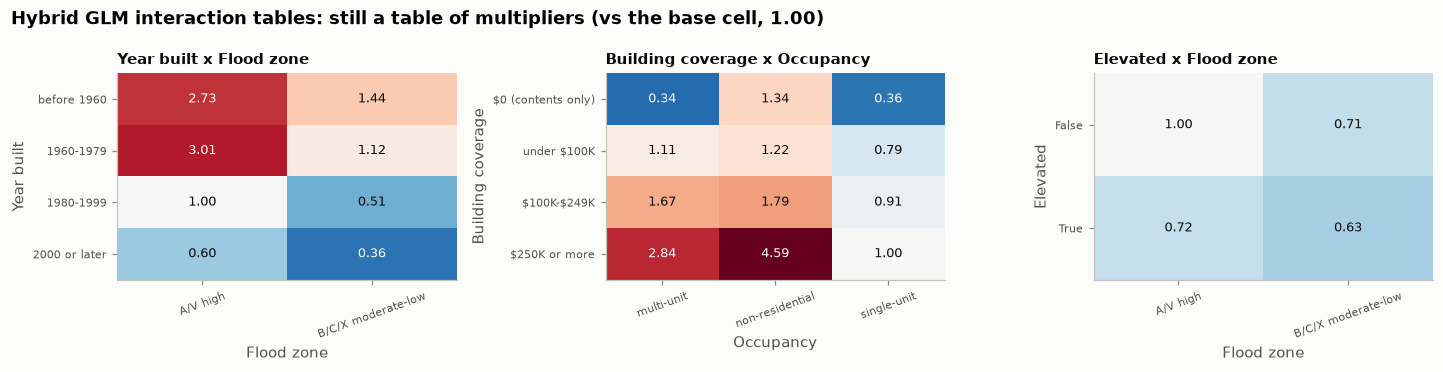

In [26]:
fig, axes = plt.subplots(1, len(IT), figsize=(4.4 * len(IT), 3.4))
axes = np.atleast_1d(axes)
for ax, (name, t) in zip(axes, IT.items()):
    rel = t["relativity"]
    im = ax.imshow(np.log(rel.to_numpy()), cmap="RdBu_r", vmin=-np.log(4), vmax=np.log(4), aspect="auto")
    for i in range(rel.shape[0]):
        for j in range(rel.shape[1]):
            v = rel.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color=INK if 0.45 < v < 2.2 else SURFACE)
    a, b = name.split(" x ")
    ax.set_xticks(range(rel.shape[1]), [str(c).replace(" residential", "").replace(" risk", "") for c in rel.columns], fontsize=7.5, rotation=20)
    ax.set_yticks(range(rel.shape[0]), rel.index, fontsize=7.5)
    ax.set_xlabel(LABELS[b])
    ax.set_ylabel(LABELS[a])
    ax.grid(False)
    ax.set_title(f"{LABELS[a]} x {LABELS[b]}", fontsize=10)
fig.suptitle("Hybrid GLM interaction tables: still a table of multipliers (vs the base cell, 1.00)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "hybrid_interactions")
plt.show()

**Result: the hybrid.**
- **Year built × zone (frequency):** kept narrowly (storm-aware p = 0.002, dev LOYO +0.08 points, better in 8 of 11 years). It reproduces exactly what the trees found: the old-building penalty is smaller outside the floodplain (1960–79 in B/C/X: interaction 0.74, the same 0.73 XGBoost showed).
- **Coverage × occupancy (severity):** the strongest result here (p < 10⁻²⁰, +1.16 points, better in all 11 years).
  - Low limits cap big buildings' claims: a multi-unit building with under $100K of cover is 1.11× the base single-family claim, not 2.10 × 0.69 = 1.45×.
  - Non-residential buildings with $250K+ of cover are 4.59×.
- **Elevated × zone (severity):** kept narrowly (p = 0.037, +0.12, 6 of 11 years). Elevation saves less outside the floodplain (0.89× vs 0.72×).
- **Frequency second pass** (Milestone 8's follow-up): no dropped feature passes. Occupancy (p = 0.054) and primary residence (p = 0.070) come closest but are worse on unseen years. The frequency model's feature set stands.

## 7. The decision, by the pre-stated rule

In [27]:
def seg_failures(model):
    """Segments (zone, elevated, coverage, occupancy, year built, credible county groups) where the model is
    outside 0.8-1.25 but the champion is inside."""
    t = SEG[SEG.shown].pivot_table(index=["feature", "level"], columns="model", values="ae")
    out = t[~t[model].between(0.8, 1.25) & t[CHAMP].between(0.8, 1.25)]
    return [f"{LABELS[f]}: {l} ({v:.2f})" for (f, l), v in out[model].items()]

hold = SC["holdout"].query("kind == 'pure_premium' and test_year == 'pooled'").set_index("model")["improvement_rebased_pct"]
dl_err = DL_TBL.set_index("challenger")
crit = []
for m in ("XGB fxs", "XGB Tweedie"):
    r = REAL.query("kind == 'pure_premium' and challenger == @m").iloc[0]
    sf = seg_failures(m)
    c = {"challenger": m,
         "1. LOYO-16 better, CI > 0": bool(r.dev_ci_low > 0), "LOYO diff (CI)": f"{r.diff_pts:+.2f} ({r.year_boot_CI})",
         "2. holdout better": bool(hold[m] > hold[CHAMP]), "holdout": f"{hold[m]:.2f} vs {hold[CHAMP]:.2f}",
         "3. cat years not worse": bool(cat.loc[("pure_premium", m), "mean"] >= cat.loc[("pure_premium", CHAMP), "mean"]),
         "cat mean": f"{cat.loc[('pure_premium', m), 'mean']:.2f} vs {cat.loc[('pure_premium', CHAMP), 'mean']:.2f}",
         "4. double lift no worse": bool(dl_err.loc[m, "end_decile_error_challenger"] <= dl_err.loc[m, "end_decile_error_champion"]),
         "end-decile error": f"{dl_err.loc[m, 'end_decile_error_challenger']:.2f} vs {dl_err.loc[m, 'end_decile_error_champion']:.2f}",
         "5. no new segment failures": len(sf) == 0, "segment failures": "; ".join(sf) or "none",
         "6. explainable for the app now": False}
    c["XGBoost qualifies on accuracy (1-5)"] = all(c[k] for k in c if k[:2] in ("1.", "2.", "3.", "4.", "5."))
    crit.append(c)
CRIT = pd.DataFrame(crit).set_index("challenger")
hrow = REAL.query("kind == 'pure_premium' and challenger == @HYB").iloc[0]
hyb_ok = bool(HT.kept.any() and hrow.diff_pts >= 0 and hold[HYB] >= hold[CHAMP])
PRODUCTION = HYB if hyb_ok else CHAMP
CRIT.T.to_csv(REP / "08_decision_criteria.csv")
print(CRIT.T.to_string())
print(f"\nHybrid: terms kept {HT.kept.sum()}, LOYO-16 diff {hrow.diff_pts:+.2f} pts ({hrow.year_boot_CI}), "
      f"holdout {hold[HYB]:.2f} vs {hold[CHAMP]:.2f} -> replaces the plain GLM: {hyb_ok}")
print("PRODUCTION MODEL:", PRODUCTION)

challenger                                                                                                            XGB fxs                                                                                                                                             XGB Tweedie
1. LOYO-16 better, CI > 0                                                                                                True                                                                                                                                                    True
LOYO diff (CI)                                                                                           +4.27 (2.86 to 5.74)                                                                                                                                   +7.56 (4.83 to 10.11)
2. holdout better                                                                                                        True                                         

**Decision, by the rule written before the results:**
- **XGBoost fails criterion 5 (segments), not only criterion 6 (explainability).**
  - Both XGBoost structures pass the accuracy, holdout, catastrophe and double-lift tests.
  - XGBoost freq × sev over-predicts buildings from 2000 or later (A/E 0.69) and mis-sizes two credible county groups (Alexandria 1.39, Chesapeake 0.78), where the champion is balanced.
  - The XGBoost Tweedie fails on newer buildings, B/C/X zones and small inland counties.
- **So the GLM ships now.** XGBoost's accuracy advantage is real, and it's the benchmark for Milestone 12. If SHAP shows its effects can be explained, and constraints fix the direction problems, it can be reconsidered.
- **The hybrid GLM replaces the plain GLM.** Its terms passed the keep rule, and it's better on 16-year LOYO (+0.4) and the holdout (10.3% vs 8.9%). The disclosure: its gain is small and not consistent across years, and it's slightly worse in catastrophe years and on its own double lift.

## 8. Save the production model
The production model is refitted on **all 16 years** (as every saved model is), with its Bühlmann–Straub county factors. It's saved as one readable JSON file, `models/production_model.json`, which the app loads through `src/models/production.py` (see `docs/production_model.md`).

In [28]:
cl = D["claims"]
if PRODUCTION == HYB:
    base = pp.fit_combined(raw, cl, spec["freq_features"], spec["sev_features"], D["FB"], D["SB"], spec["freq_inter"], spec["sev_inter"])
else:
    base = pp.fit_combined(raw, cl, D["FF"], D["SF"], D["FB"], D["SB"])
prod, ctab, cpar = pp.with_county_factors(base, raw, cl, "buhlmann_straub")
assert np.allclose(prod.rate(GRID_CELLS), ALL["pp/" + PRODUCTION].rate(GRID_CELLS))
assert np.isclose(prod.predict(raw, county=True).sum(), raw[X.LOSS].sum(), rtol=1e-6)   # balances to actual total
names = {r["county"]: r["name"] for r in pj["county_table"]}
ctab = ctab.copy()
ctab.index = ctab.index.astype(str)
ctab["name"] = ctab.index.map(names)
card_scores = CARD["pure_premium"].loc[PRODUCTION]
card = {"name": f"Flood loss cost model: {PRODUCTION}", "version": "1.0", "milestone": 11, "created": str(date.today()),
        "structure": "frequency GLM (Poisson, log link, exposure offset) x severity GLM (Gamma, log link) x large-loss load x ICC bridge x off-balance x Buhlmann-Straub county factor",
        "frequency_features": base.freq.spec.features, "frequency_interactions": base.freq.spec.interactions,
        "severity_features": base.sev.spec.features, "severity_interactions": base.sev.spec.interactions,
        "fitted_on_years": [2010, 2025], "dollars": "2025 (CPI-U)", "level": "average year",
        "data_file_sha256_16": h,
        "validation": {"loyo16_mean_improvement_pct": float(card_scores["LOYO-16 mean %"]), "loyo16_gini": float(card_scores["LOYO-16 Gini"]),
                       "holdout_2021_2025_improvement_pct": float(card_scores["holdout %"]), "holdout_gini": float(card_scores["holdout Gini"]),
                       "yardstick": "re-based Tweedie (p = 1.5) deviance improvement vs no-features model; each unseen year once"},
        "county_method": "buhlmann_straub", "county_parameters": cpar,
        "why_not_xgboost": "XGBoost is more accurate on unseen years (see reports/08_model_comparison.md) but has no relativity table; revisit after SHAP (Milestone 12).",
        "report": "reports/08_model_comparison.md"}
production.save(prod, card, ctab)
pm = production.load()
VB = pd.read_csv(REP / "06_rating_worksheets.csv", dtype={"county": str})
for c in pm.features:
    if c not in VB:
        VB[c] = (pm.freq.spec.bases | pm.sev.spec.bases)[c]
VB["post_firm"] = VB.get("post_firm", "False")
new = pm.predict(VB.astype({c: str for c in pm.features}))
VB["production_expected_annual_loss"] = new["pure_premium"].to_numpy()
card["check_virginia_beach_worksheet"] = float(pm.explain(VB.astype({c: str for c in pm.features}).iloc[0]).attrs["pure_premium"])
production.save(prod, card, ctab)
print(VB[["profile", "expected_annual_loss", "production_expected_annual_loss"]].round(0).to_string(index=False))
VB[["profile", "expected_annual_loss", "production_expected_annual_loss"]].to_csv(REP / "08_rating_worksheets_production.csv", index=False)
print(f"\nmodels/production_model.json: {(ROOT / 'models' / 'production_model.json').stat().st_size / 1024:.0f} KB")
pm.explain(VB.astype({c: str for c in pm.features}).iloc[0]).round(4)

                                                  profile  expected_annual_loss  production_expected_annual_loss
      Virginia Beach, 1960s ranch house in the floodplain                 585.0                            598.0
                      Norfolk, newer elevated second home                  57.0                             44.0
Roanoke, older bungalow outside the floodplain, low cover                  90.0                            105.0
  Newport News, 1980s condo building (association policy)                 579.0                            656.0
               Arlington, 1970s small commercial building                 516.0                            269.0

models/production_model.json: 76 KB


,part,term,value
0,frequency,base claims per policy-year (average year),0.0046
1,frequency,flood_zone_group = A/V high risk,1.0000
2,frequency,construction_band = 1960-1979,3.0063
3,frequency,floors_group = 1,0.8902
4,severity,"base claim size, 2025 $ (average year)",27462.6061
5,severity,occupancy_group = single-unit residential,1.0000
6,severity,construction_band = 1960-1979,1.2840
7,severity,building_coverage_band = $250K or more,1.0000
8,severity,flood_zone_group = A/V high risk,1.0000
9,severity,floors_group = 1,1.1317


**Result: the production model.**
- Saved as `models/production_model.json` (76 KB) and reproduced by `src/models/production.py`. Its worksheets reconcile with `predict()`.
- **How the five Milestone 9 worksheets change:**
  - the Virginia Beach house goes from $585 to $598;
  - the Newport News condo building from $579 to $656 (multi-unit with $250K+ cover);
  - **the Arlington commercial building halves, from $516 to $269.** Coverage × occupancy says a non-residential building with $100K–249K of cover has 1.79× base claim size, not 3.07 × 0.85 = 2.61×.

  These are the cells where the interaction matters most.

## Summary
- **Accuracy:** XGBoost is genuinely more accurate on unseen years, by about 4 points of deviance improvement for pure premium (CI 2.9–5.7, 15 of 16 years), mostly through claim size.
- **Why the GLM still ships:** XGBoost fails the pre-stated segment check (newer buildings, two county groups). It also moves the wrong way on elevation and coverage for a large share of cells, changes with the random seed, and can't produce a rating worksheet.
- **The app uses the hybrid GLM** (frequency × severity with three interaction terms + Bühlmann–Straub county factor). It keeps a relativity table and closes about a tenth of the gap on 16-year LOYO and about a third on the holdout.
- **Next:** Milestone 12 (SHAP) decides whether XGBoost's extra accuracy can be explained well enough to use, for example as a monitoring benchmark or a source of further GLM interactions.

Full write-up: `reports/08_model_comparison.md`.